# Treino — LateFusionSpatialCNN — ablação por tamanho de patch

Versão para testar LateFusionCNN em vários tamanhos de patch: 3×3, 5×5, 7×7, 11×11 e 15×15.

O código lê GeoTIFFs multibanda gerados em `_example_patches_by_size/patch_NxN`, mantém a mesma seed, a mesma validação cruzada estratificada por região + classe de altura e guarda os resultados numa pasta separada por tamanho de patch.


In [1]:
# ============================================================
# 1. IMPORTS E CONFIGURAÇÃO GLOBAL
# ============================================================

import os
import time
import json
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
import geopandas as gpd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# -----------------------------
# Caminhos
# -----------------------------
# Pasta que contém:
#   patch_3x3/
#   patch_5x5/
#   patch_7x7/
#   patch_11x11/
#   patch_15x15/
PATCH_BASE_DIR = Path(r"D:\Tese_data_refinada\_example_patches_by_size")
VALIDATION_DIR = Path(r"D:\Tese_data_refinada\Areas_gpkg")

OUTPUT_BASE_DIR = Path("outputs_fch/spacial_cnn/cv_global_misturado_late_fusion_cnn_patch_size_ablation")
OUTPUT_BASE_DIR.mkdir(parents=True, exist_ok=True)

# Este OUTPUT_DIR é atualizado automaticamente dentro de cada patch size.
OUTPUT_DIR = OUTPUT_BASE_DIR

# -----------------------------
# Experiência
# -----------------------------
SEED = 42
TARGET_COLUMN = "rh_opt_098"
TARGET_SCALE = 100.0   # cm → metros

# Tamanhos de patch a testar.
# Para testar só um, por exemplo: PATCH_SIZES_TO_RUN = [5]
PATCH_SIZES_TO_RUN = [3, 5, 7, 11, 15,21]

# Comparação justa entre tamanhos:
# False = cada patch size usa todos os pontos válidos disponíveis.
# True  = todos os patch sizes usam apenas os pontos comuns a todos os tamanhos.
USE_COMMON_POINTS_ACROSS_PATCH_SIZES = True

# Cross-validation
N_SPLITS = 5
N_HEIGHT_BINS = 5

# Por defeito corre apenas a versão com augmentation, para comparar arquiteturas mantendo o resto igual.
# Para repetir a ablation completa, usa: ABLATION_AUGMENTATION_MODES = ["aug_on", "aug_off"]
ABLATION_AUGMENTATION_MODES = ["aug_on"]

# Plots
PLOT_EACH_FOLD = False
SAVE_PLOTS = True

# -----------------------------
# Hiperparâmetros
# -----------------------------
BATCH_SIZE = 64
LR = 3e-4
WEIGHT_DECAY = 0.0
EPOCHS = 70
PATIENCE = 15
LOG_EVERY = 5      # imprime métricas completas a cada N épocas

# -----------------------------
# Hardware
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM disponível: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)


Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3060
VRAM disponível: 12.9 GB


In [2]:
# ============================================================
# 2. DATASET E AUGMENTATION
# ============================================================

class FCHDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.float32)
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx].copy()
        if self.transform is not None:
            x = self.transform(x)
        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(self.y[idx], dtype=torch.float32),
        )


def base_augmentation(x):
    """Rotações e flips aleatórios. Usar apenas no treino."""
    k = np.random.randint(0, 4)
    if k > 0:
        x = np.rot90(x, k, axes=(1, 2)).copy()

    if np.random.rand() > 0.5:
        x = np.flip(x, axis=2).copy()

    if np.random.rand() > 0.5:
        x = np.flip(x, axis=1).copy()

    return x


def get_train_transform(augmentation_mode):
    """Devolve a transformação de treino para a experiência de ablation."""
    if augmentation_mode == "aug_on":
        return base_augmentation

    if augmentation_mode == "aug_off":
        return None

    raise ValueError(
        f"augmentation_mode inválido: {augmentation_mode}. "
        "Usa 'aug_on' ou 'aug_off'."
    )


In [3]:
# ============================================================
# 3. CARREGAMENTO DOS TIFs
# ============================================================

def extract_point_id(filename):
    m = re.search(r"point_(\d+)_", filename)
    if m is None:
        raise ValueError(f"Não consegui extrair point_id de: {filename}")
    return int(m.group(1))


def build_target_dict(gdf, target_column):
    possible_id_cols = ["point_id", "POINT_ID", "id", "ID", "fid", "FID"]
    id_col = next((c for c in possible_id_cols if c in gdf.columns), None)

    ids = gdf[id_col].astype(int).values if id_col else gdf.index.astype(int).values
    targets = gdf[target_column].values

    return {
        int(pid): float(t)
        for pid, t in zip(ids, targets)
        if not pd.isna(t)
    }


def canonical_band_name(name):
    """
    Normaliza nomes de bandas para comparar regiões.

    Remove:
      - prefixo da área, se existir antes de 20200000;
      - sufixos técnicos que não mudam a variável, como _A e _Mosaic.

    Exemplo:
      SerraLousa_20200000_S1SLC_COHVH_Mosaic -> 20200000_S1SLC_COHVH
      Mafra_20200000_S1SLC_COHVH_A           -> 20200000_S1SLC_COHVH
    """
    s = str(name)

    # Fica só com a parte a partir do ano, se existir.
    m = re.search(r"20\d{6}_.+", s)
    if m:
        s = m.group(0)

    # Remove sufixos finais que representam versão/produto, não variável física.
    s = re.sub(r"_(A|MOSAIC)$", "", s, flags=re.IGNORECASE)

    return s


def get_valid_band_indices(metadata_path):
    with open(metadata_path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    raster_names = meta.get("raster_names", [])

    valid_indices = [
        i for i, name in enumerate(raster_names)
        if "CHM" not in name.upper()
        and "LIDAR" not in name.upper()
        and "OTHER" not in name.upper()
    ]

    removed = [
        name for name in raster_names
        if "CHM" in name.upper()
        or "LIDAR" in name.upper()
        or "OTHER" in name.upper()
    ]

    if removed:
        print(f"   Bandas removidas (leakage): {removed}")

    return valid_indices, raster_names


def find_common_region_point_ids(patch_base_dir, patch_sizes, validation_dir, target_column="rh_opt_098"):
    """
    Encontra os pontos (região, point_id) presentes em todos os tamanhos de patch.
    Não lê os rasters para memória; apenas varre os nomes dos GeoTIFFs.
    """
    patch_base_dir = Path(patch_base_dir)
    validation_dir = Path(validation_dir)

    ids_by_size = {}

    for patch_size in patch_sizes:
        raw_base_dir = patch_base_dir / f"patch_{patch_size}x{patch_size}"
        ids_this_size = set()

        if not raw_base_dir.exists():
            raise FileNotFoundError(f"Pasta não encontrada: {raw_base_dir}")

        for area_dir in sorted(raw_base_dir.iterdir()):
            if not area_dir.is_dir():
                continue

            area_name = area_dir.name
            gpkg_path = validation_dir / f"{area_name}_HEIGHT_Dataset.gpkg"
            if not gpkg_path.exists():
                continue

            gdf = gpd.read_file(gpkg_path)
            target_dict = build_target_dict(gdf, target_column)

            for tif in area_dir.rglob("*.tif"):
                pid = extract_point_id(tif.name)
                if pid in target_dict:
                    ids_this_size.add((area_name, int(pid)))

        ids_by_size[patch_size] = ids_this_size
        print(f"Patch {patch_size}x{patch_size}: {len(ids_this_size)} pontos com target")

    common_ids = set.intersection(*ids_by_size.values())
    print(f"\nPontos comuns a todos os patch sizes: {len(common_ids)}")

    return common_ids, ids_by_size


def load_all_regions_tifs(
    raw_base_dir,
    validation_dir,
    target_column="rh_opt_098",
    allowed_region_point_ids=None,
):
    raw_base_dir = Path(raw_base_dir)
    validation_dir = Path(validation_dir)

    if not raw_base_dir.exists():
        raise FileNotFoundError(f"Pasta de patches não encontrada: {raw_base_dir}")

    X_list, y_list, region_list, pid_list = [], [], [], []
    channels_ref = None
    band_names_ref = None
    canonical_band_names_ref = None

    print("-> A ler TIFs e cruzar com GeoPackages...")
    print(f"   Pasta: {raw_base_dir}")

    for area_dir in sorted(raw_base_dir.iterdir()):
        if not area_dir.is_dir():
            continue

        area_name = area_dir.name
        gpkg_path = validation_dir / f"{area_name}_HEIGHT_Dataset.gpkg"

        if not gpkg_path.exists():
            print(f"   [{area_name}] GeoPackage não encontrado — ignorado.")
            continue

        metas = list(area_dir.glob("*.json"))
        if not metas:
            print(f"   [{area_name}] metadata JSON não encontrado — ignorado.")
            continue

        print(f"\nÁrea: {area_name}")

        gdf = gpd.read_file(gpkg_path)
        target_dict = build_target_dict(gdf, target_column)
        valid_idx, raster_names = get_valid_band_indices(metas[0])
        valid_band_names = [raster_names[i] for i in valid_idx]
        canonical_band_names = [canonical_band_name(name) for name in valid_band_names]

        if channels_ref is None:
            channels_ref = len(valid_idx)
            band_names_ref = valid_band_names
            canonical_band_names_ref = canonical_band_names
            print("   Área de referência para ordem das bandas.")
        else:
            if len(valid_idx) != channels_ref:
                raise ValueError(
                    f"Canais incompatíveis em {area_name}: "
                    f"esperado {channels_ref}, obtido {len(valid_idx)}"
                )

            same_order = canonical_band_names == canonical_band_names_ref
            same_set = set(canonical_band_names) == set(canonical_band_names_ref)

            if not same_order:
                if not same_set:
                    missing = sorted(set(canonical_band_names_ref) - set(canonical_band_names))
                    extra = sorted(set(canonical_band_names) - set(canonical_band_names_ref))
                    raise ValueError(
                        f"Bandas incompatíveis em {area_name}.\n"
                        f"Faltam: {missing[:20]}\n"
                        f"Extra: {extra[:20]}"
                    )

                # Se tiver as mesmas bandas mas em ordem diferente, reordena.
                key_to_raster_index = {
                    canonical_band_name(name): i
                    for i, name in enumerate(raster_names)
                }
                valid_idx = [key_to_raster_index[key] for key in canonical_band_names_ref]
                print(f"   AVISO: bandas reordenadas em {area_name} para seguir a referência.")
            else:
                print("   Ordem das bandas OK.")

        n_loaded = 0
        n_no_target = 0
        n_filtered_common = 0

        for tif in sorted(area_dir.rglob("*.tif")):
            pid = extract_point_id(tif.name)

            if pid not in target_dict:
                n_no_target += 1
                continue

            if allowed_region_point_ids is not None and (area_name, int(pid)) not in allowed_region_point_ids:
                n_filtered_common += 1
                continue

            with rasterio.open(tif) as src:
                patch = src.read().astype(np.float32)[valid_idx]

            X_list.append(patch)
            y_list.append(target_dict[pid])
            region_list.append(area_name)
            pid_list.append(pid)
            n_loaded += 1

        msg = f"   Carregados: {n_loaded} | Sem target: {n_no_target}"
        if allowed_region_point_ids is not None:
            msg += f" | Fora da interseção comum: {n_filtered_common}"
        print(msg)

    if not X_list:
        raise RuntimeError("Nenhum patch carregado.")

    X = np.stack(X_list).astype(np.float32)
    y = np.array(y_list, dtype=np.float32)
    regions = np.array(region_list)
    point_ids = np.array(pid_list)

    print(f"\nResumo: X={X.shape} | y={y.shape} | regiões={sorted(set(regions))}")
    print(f"NaNs em X: {np.isnan(X).mean() * 100:.6f}%")

    return X, y, regions, point_ids, band_names_ref


In [4]:
# ============================================================
# 4. NORMALIZAÇÃO SEM LEAKAGE
# ============================================================

def normalize_from_train(X_train_raw, X_val_raw):
    mean = np.nanmean(X_train_raw, axis=(0, 2, 3), keepdims=True)
    std  = np.nanstd(X_train_raw,  axis=(0, 2, 3), keepdims=True)
    std  = np.where(std == 0, 1e-6, std)

    X_train = np.nan_to_num((X_train_raw - mean) / std, nan=0., posinf=0., neginf=0.).astype(np.float32)
    X_val   = np.nan_to_num((X_val_raw   - mean) / std, nan=0., posinf=0., neginf=0.).astype(np.float32)

    print(f"Normalização concluída | média_treino≈{np.mean(X_train):.5f} | std_treino≈{np.std(X_train):.5f}")
    return X_train, X_val, mean, std

In [5]:
# ============================================================
# 5. ARQUITETURA — LATE FUSION SPATIAL CNN
# ============================================================

from collections import OrderedDict


def infer_sensor_group_from_name(name):
    """Heurística para agrupar canais por tipo de sensor/variável."""
    u = str(name).upper()

    # Sentinel-1 / SAR
    if any(k in u for k in ["SENTINEL1", "SENTINEL-1", "S1", "_VV", "_VH", "VV_", "VH_", "SAR"]):
        return "S1_SAR"

    # Sentinel-2 / óptico/multiespectral
    s2_band_tokens = [f"B{i:02d}" for i in range(1, 13)] + ["B8A", "NDVI", "EVI", "NDWI", "NDMI", "NBR"]
    if any(k in u for k in ["SENTINEL2", "SENTINEL-2", "S2"] + s2_band_tokens):
        return "S2_OPTICAL"

    # Topografia ou variáveis auxiliares não derivadas diretamente do target
    if any(k in u for k in ["DEM", "DTM", "DSM", "ELEV", "ELEVATION", "SLOPE", "ASPECT", "TPI", "TRI"]):
        return "TOPOGRAPHY"

    # Máscaras/indicadores de disponibilidade
    if any(k in u for k in ["MASK", "VALID", "AVAIL", "NODATA"]):
        return "MASKS"

    return "OTHER"


def infer_late_fusion_channel_groups(band_names):
    """
    Cria grupos de canais para late fusion.

    Cada grupo será processado por uma branch CNN separada. A fusão só acontece
    depois das features espaciais extraídas por cada branch.
    """
    groups = OrderedDict()

    for idx, name in enumerate(band_names):
        group = infer_sensor_group_from_name(name)
        groups.setdefault(group, []).append(idx)

    # Ordenação fixa para reprodutibilidade e leitura dos outputs
    preferred_order = ["S1_SAR", "S2_OPTICAL", "TOPOGRAPHY", "MASKS", "OTHER"]
    ordered = OrderedDict()
    for group in preferred_order:
        if group in groups:
            ordered[group] = groups[group]
    for group in groups:
        if group not in ordered:
            ordered[group] = groups[group]

    print("\nGrupos de canais para late fusion:")
    for group, idxs in ordered.items():
        print(f"  {group}: {len(idxs)} canais")

    if len(ordered) < 2:
        print(
            "AVISO: só foi detetado um grupo de canais. "
            "Confirma os nomes em band_names_ref; neste caso a arquitetura não faz late fusion real."
        )

    return ordered


class SensorSpatialBranch(nn.Module):
    """Branch CNN pequena para um grupo de canais."""
    def __init__(self, in_channels: int, branch_channels: int = 32):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_channels, branch_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.GELU(),

            nn.Conv2d(branch_channels, branch_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.GELU(),

            nn.Conv2d(branch_channels, branch_channels, kernel_size=3, padding=2, dilation=2, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.GELU(),

            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten(),
        )

        self.out_features = branch_channels * 2 * 2

    def forward(self, x):
        return self.net(x)


class LateFusionSpatialCNN(nn.Module):
    """
    Late fusion CNN.

    Fluxo:
      grupo S1/SAR       -> branch CNN -> features
      grupo S2/óptico    -> branch CNN -> features
      grupo topo/outros  -> branch CNN -> features
      concatenação das features -> MLP final -> altura
    """
    def __init__(self, in_channels: int, channel_groups, branch_channels: int = 32):
        super().__init__()

        self.group_names = list(channel_groups.keys())
        self.group_indices = [list(channel_groups[g]) for g in self.group_names]

        used_channels = sorted([idx for idxs in self.group_indices for idx in idxs])
        expected_channels = list(range(in_channels))
        if used_channels != expected_channels:
            raise ValueError("Os grupos de canais não cobrem exatamente todos os canais de entrada.")

        self.branches = nn.ModuleDict()
        total_features = 0

        for group_name, idxs in zip(self.group_names, self.group_indices):
            module_key = re.sub(r"[^A-Za-z0-9_]", "_", group_name)
            branch = SensorSpatialBranch(len(idxs), branch_channels=branch_channels)
            self.branches[module_key] = branch
            total_features += branch.out_features

        self.module_keys = [re.sub(r"[^A-Za-z0-9_]", "_", g) for g in self.group_names]

        self.regressor = nn.Sequential(
            nn.Linear(total_features, 128, bias=False),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = []

        for module_key, indices in zip(self.module_keys, self.group_indices):
            x_group = x[:, indices, :, :]
            features.append(self.branches[module_key](x_group))

        x = torch.cat(features, dim=1)
        return self.regressor(x).squeeze(1)


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parâmetros totais: {total:,} | treináveis: {trainable:,}")
    return total, trainable

In [6]:
# ============================================================
# 6. FUNÇÕES DE MÉTRICAS E TREINO
# ============================================================

def regression_metrics(y_true, y_pred):
    y_true_np = np.array(y_true).flatten()
    y_pred_np = np.array(y_pred).flatten()

    rmse = float(np.sqrt(mean_squared_error(y_true_np, y_pred_np)))
    mae = float(mean_absolute_error(y_true_np, y_pred_np))
    bias = float(np.mean(y_pred_np - y_true_np))

    if len(y_true_np) > 1 and len(np.unique(y_true_np)) > 1:
        r2 = float(r2_score(y_true_np, y_pred_np))
        covariancia = float(np.cov(y_true_np, y_pred_np)[0, 1])
    else:
        r2 = float("nan")
        covariancia = float("nan")

    y_true_mean = float(np.mean(y_true_np))
    pct_rmse = (rmse / y_true_mean) * 100 if y_true_mean > 0 else float("nan")

    return {
        "n": int(len(y_true_np)),
        "RMSE": rmse,
        "%RMSE": pct_rmse,
        "MAE": mae,
        "R2": r2,
        "Bias": bias,
        "Covariancia": covariancia,
    }


def _eval_loader(model, loader):
    """Devolve (y_true, y_pred) em numpy para um loader completo."""
    model.eval()
    all_preds, all_targets = [], []

    with torch.no_grad():
        for bX, by in loader:
            all_preds.append(model(bX.to(device)).cpu().numpy())
            all_targets.append(by.numpy())

    return np.concatenate(all_targets), np.concatenate(all_preds)


def train_spacialcnn_cnn(
    model,
    train_loader,
    val_loader,
    model_name,
    epochs=40,
    patience=15,
    lr=3e-4,
    weight_decay=0.0,
    log_every=5,
):
    """
    Treina a SpacialCNN com early stopping.

    A métrica usada para guardar o melhor checkpoint é o MSE de validação.
    """
    model = model.to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=5,
    )

    ckpt_path = OUTPUT_DIR / f"ckpt_{model_name}.pth"

    best_val_loss = np.inf
    best_epoch = 0
    epochs_no_impr = 0

    history = {
        "epoch": [],
        "train_mse": [],
        "val_mse": [],
        "val_rmse": [],
        "val_pct_rmse": [],
        "val_mae": [],
        "val_r2": [],
        "lr": [],
    }

    y_val_all = np.concatenate([by.numpy() for _, by in val_loader])
    y_val_mean = float(np.mean(y_val_all))

    header = (
        f"{'Época':>6}  {'MSE_tr':>8}  {'MSE_val':>8}  "
        f"{'RMSE_val':>9}  {'%RMSE':>6}  {'MAE':>7}  {'R²':>6}  "
        f"{'LR':>9}  {'s/ep':>5}  {'ETA':>6}"
    )

    print(f"\n{'─' * len(header)}")
    print(header)
    print(f"{'─' * len(header)}")

    epoch_times = []

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        model.train()
        train_loss_sum = 0.0

        for bX, by in train_loader:
            bX, by = bX.to(device), by.to(device)

            optimizer.zero_grad()
            loss = criterion(model(bX), by)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * bX.size(0)

        train_mse = train_loss_sum / len(train_loader.dataset)

        y_true_v, y_pred_v = _eval_loader(model, val_loader)

        val_mse = float(mean_squared_error(y_true_v, y_pred_v))
        val_rmse = float(np.sqrt(val_mse))
        val_pct_rmse = (val_rmse / y_val_mean) * 100 if y_val_mean > 0 else float("nan")
        val_mae = float(mean_absolute_error(y_true_v, y_pred_v))
        val_r2 = float(r2_score(y_true_v, y_pred_v))

        scheduler.step(val_mse)
        current_lr = optimizer.param_groups[0]["lr"]

        elapsed = time.time() - t0
        epoch_times.append(elapsed)

        remaining_epochs = epochs - epoch
        avg_ep_time = np.mean(epoch_times[-10:])
        eta_s = remaining_epochs * avg_ep_time
        eta_str = f"{int(eta_s // 60)}m{int(eta_s % 60):02d}s" if eta_s >= 60 else f"{eta_s:.0f}s"

        improved = val_mse < best_val_loss

        if improved:
            best_val_loss = val_mse
            best_epoch = epoch
            epochs_no_impr = 0
            torch.save(model.state_dict(), ckpt_path)
            flag = " ⭐"
        else:
            epochs_no_impr += 1
            flag = ""

        history["epoch"].append(epoch)
        history["train_mse"].append(train_mse)
        history["val_mse"].append(val_mse)
        history["val_rmse"].append(val_rmse)
        history["val_pct_rmse"].append(val_pct_rmse)
        history["val_mae"].append(val_mae)
        history["val_r2"].append(val_r2)
        history["lr"].append(current_lr)

        if epoch == 1 or epoch % log_every == 0 or improved:
            print(
                f"{epoch:>6}  {train_mse:>8.4f}  {val_mse:>8.4f}  "
                f"{val_rmse:>8.3f}m  {val_pct_rmse:>5.1f}%  "
                f"{val_mae:>6.3f}m  {val_r2:>6.3f}  "
                f"{current_lr:>9.2e}  {elapsed:>4.1f}s  {eta_str:>6}{flag}"
            )

        if epochs_no_impr >= patience:
            print(f"\nEarly stopping na época {epoch} (sem melhoria há {patience} épocas).")
            break

    print(f"{'─' * len(header)}")
    print(
        f"Melhor época: {best_epoch} | "
        f"Melhor val MSE: {best_val_loss:.4f} | "
        f"RMSE: {np.sqrt(best_val_loss):.3f}m"
    )

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model, pd.DataFrame(history)


def evaluate_model(model, val_loader, model_name):
    y_true, y_pred = _eval_loader(model, val_loader)

    metrics = regression_metrics(y_true, y_pred)

    results_df = pd.DataFrame([
        {
            "model": model_name,
            "split": "val",
            **metrics,
        }
    ])

    preds_dict = {
        "val": {
            "y_true": y_true,
            "y_pred": y_pred,
        }
    }

    return results_df, preds_dict


In [7]:
# ============================================================
# 7. GRÁFICOS
# ============================================================

PLOTS_DIR = OUTPUT_DIR / "figuras"


def finalize_figure(path=None):
    """Mostra a figura e, se SAVE_PLOTS=True, guarda-a no disco."""
    plt.tight_layout()

    if SAVE_PLOTS and path is not None:
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(path, dpi=150, bbox_inches="tight")
        print(f"Figura guardada: {path}")

    plt.show()


def clean_label(text):
    """Nome seguro para ficheiros."""
    return str(text).replace(" ", "_").replace("/", "_").replace("|", "_")


def format_height_class_labels(bin_edges, target_scale=100.0):
    """Cria labels legíveis para as classes de altura."""
    labels = {}
    for i in range(len(bin_edges) - 1):
        lo = bin_edges[i] / target_scale
        hi = bin_edges[i + 1] / target_scale
        labels[i] = f"C{i}: {lo:.1f}-{hi:.1f} m"
    return labels


def plot_learning_curves(hist, model_name, split_label):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(hist["epoch"], hist["train_mse"], label="treino")
    axes[0].plot(hist["epoch"], hist["val_mse"], label="validação", linestyle="--")
    axes[0].set(title="MSE", xlabel="Época", ylabel="MSE")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(hist["epoch"], hist["val_rmse"], label="RMSE (m)")
    axes[1].plot(hist["epoch"], hist["val_mae"], label="MAE (m)", linestyle="--")
    axes[1].set(title="RMSE & MAE (validação)", xlabel="Época", ylabel="m")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    axes[2].plot(hist["epoch"], hist["val_pct_rmse"], label="%RMSE")
    ax2r = axes[2].twinx()
    ax2r.plot(hist["epoch"], hist["val_r2"], linestyle=":", label="R²")
    axes[2].set(title="%RMSE & R² (validação)", xlabel="Época", ylabel="%RMSE")
    ax2r.set_ylabel("R²")
    axes[2].legend(loc="upper right")
    ax2r.legend(loc="upper center")
    axes[2].grid(alpha=0.3)

    plt.suptitle(f"{model_name} — {split_label}", fontsize=12, fontweight="bold")
    finalize_figure(PLOTS_DIR / f"curvas_{clean_label(model_name)}_{clean_label(split_label)}.png")


def plot_true_vs_pred(y_true, y_pred, model_name, split_name, split_label):
    mn = min(np.min(y_true), np.min(y_pred))
    mx = max(np.max(y_true), np.max(y_pred))

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(y_true, y_pred, alpha=0.45, s=12)
    plt.plot([mn, mx], [mn, mx], "--k", linewidth=1)
    plt.xlabel("Altura real (m)")
    plt.ylabel("Altura prevista (m)")
    plt.title(f"{model_name} | {split_name} | {split_label}\nRMSE={rmse:.3f} m  R²={r2:.3f}")
    plt.grid(alpha=0.3)

    finalize_figure(PLOTS_DIR / f"{clean_label(model_name)}_{clean_label(split_name)}_{clean_label(split_label)}_real_vs_previsto.png")


def plot_residuals(y_true, y_pred, model_name, split_name, split_label):
    residuals = y_pred - y_true

    plt.figure(figsize=(6, 4.5))
    plt.scatter(y_pred, residuals, alpha=0.45, s=12)
    plt.axhline(0, linestyle="--", color="k", linewidth=1)
    plt.xlabel("Altura prevista (m)")
    plt.ylabel("Resíduo (previsto - real) (m)")
    plt.title(f"Resíduos | {model_name} | {split_name} | {split_label}")
    plt.grid(alpha=0.3)

    finalize_figure(PLOTS_DIR / f"{clean_label(model_name)}_{clean_label(split_name)}_{clean_label(split_label)}_residuos.png")


def plot_pooled_true_vs_pred(predictions_df, augmentation_mode):
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()

    plot_true_vs_pred(
        df["y_true_m"].to_numpy(),
        df["y_pred_m"].to_numpy(),
        model_name="LateFusionSpatialCNN",
        split_name="val_pooled",
        split_label=augmentation_mode,
    )


def plot_pooled_residuals(predictions_df, augmentation_mode):
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()

    plot_residuals(
        df["y_true_m"].to_numpy(),
        df["y_pred_m"].to_numpy(),
        model_name="LateFusionSpatialCNN",
        split_name="val_pooled",
        split_label=augmentation_mode,
    )


def plot_true_pred_histogram(predictions_df, augmentation_mode, n_bins=40):
    """Histograma da distribuição real vs prevista com bins comuns."""
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()

    y_true = df["y_true_m"].to_numpy()
    y_pred = df["y_pred_m"].to_numpy()

    print(f"Histograma — {augmentation_mode} | N real={len(y_true)} | N previsto={len(y_pred)}")

    min_val = min(np.min(y_true), np.min(y_pred))
    max_val = max(np.max(y_true), np.max(y_pred))
    bins = np.linspace(min_val, max_val, n_bins + 1)

    plt.figure(figsize=(7, 4.5))
    plt.hist(y_true, bins=bins, alpha=0.55, label="Real")
    plt.hist(y_pred, bins=bins, alpha=0.55, label="Previsto")
    plt.xlabel("Altura (m)")
    plt.ylabel("Nº de amostras")
    plt.title(f"Distribuição de alturas reais e previstas — {augmentation_mode}")
    plt.legend()
    plt.grid(alpha=0.3)

    finalize_figure(PLOTS_DIR / f"hist_real_vs_previsto_{augmentation_mode}.png")

def plot_metric_by_region(metrics_by_region, augmentation_mode, metric="RMSE"):
    """Barplot de uma métrica por região."""
    df = metrics_by_region[metrics_by_region["augmentation"] == augmentation_mode].copy()
    df = df.sort_values(metric, ascending=False)

    plt.figure(figsize=(8, 4.8))
    plt.bar(df["region"], df[metric])
    plt.xlabel("Região")
    plt.ylabel(metric)
    plt.title(f"{metric} por região — {augmentation_mode}")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)

    finalize_figure(PLOTS_DIR / f"{metric.lower()}_por_regiao_{augmentation_mode}.png")


def plot_metric_by_height_class(metrics_by_height_class, augmentation_mode, metric="RMSE", height_class_labels=None):
    """Barplot de uma métrica por classe de altura."""
    df = metrics_by_height_class[metrics_by_height_class["augmentation"] == augmentation_mode].copy()
    df = df.sort_values("height_class")

    xlabels = df["height_class"].astype(str).tolist()
    if height_class_labels is not None:
        xlabels = [height_class_labels.get(int(c), str(c)) for c in df["height_class"]]

    plt.figure(figsize=(8, 4.8))
    plt.bar(xlabels, df[metric])
    plt.xlabel("Classe de altura")
    plt.ylabel(metric)
    plt.title(f"{metric} por classe de altura — {augmentation_mode}")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)

    finalize_figure(PLOTS_DIR / f"{metric.lower()}_por_classe_altura_{augmentation_mode}.png")


def plot_residual_boxplot_by_height_class(predictions_df, augmentation_mode, height_class_labels=None):
    """Boxplot dos resíduos por classe de altura."""
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()
    classes = sorted(df["height_class"].unique())
    data = [df[df["height_class"] == c]["residual_m"].to_numpy() for c in classes]

    labels = [str(c) for c in classes]
    if height_class_labels is not None:
        labels = [height_class_labels.get(int(c), str(c)) for c in classes]

    plt.figure(figsize=(8, 4.8))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.axhline(0, linestyle="--", color="k", linewidth=1)
    plt.xlabel("Classe de altura")
    plt.ylabel("Resíduo (previsto - real) (m)")
    plt.title(f"Distribuição dos resíduos por classe de altura — {augmentation_mode}")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)

    finalize_figure(PLOTS_DIR / f"boxplot_residuos_por_classe_altura_{augmentation_mode}.png")


def plot_residual_boxplot_by_region(predictions_df, augmentation_mode):
    """Boxplot dos resíduos por região."""
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()
    regions = sorted(df["region"].unique())
    data = [df[df["region"] == r]["residual_m"].to_numpy() for r in regions]

    plt.figure(figsize=(8, 4.8))
    plt.boxplot(data, labels=regions, showfliers=False)
    plt.axhline(0, linestyle="--", color="k", linewidth=1)
    plt.xlabel("Região")
    plt.ylabel("Resíduo (previsto - real) (m)")
    plt.title(f"Distribuição dos resíduos por região — {augmentation_mode}")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)

    finalize_figure(PLOTS_DIR / f"boxplot_residuos_por_regiao_{augmentation_mode}.png")


def plot_cv_metric_evolution(all_histories, augmentation_mode, metric="val_rmse"):
    """
    Mostra a evolução média de uma métrica de validação ao longo das épocas.
    Como alguns folds podem parar mais cedo, calcula a média apenas das épocas disponíveis.
    """
    rows = []
    for (mode, fold), hist in all_histories.items():
        if mode != augmentation_mode:
            continue
        df_hist = hist[["epoch", metric]].copy()
        df_hist["fold"] = fold
        rows.append(df_hist)

    if not rows:
        return

    hist_df = pd.concat(rows, ignore_index=True)
    summary = (
        hist_df
        .groupby("epoch")[metric]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    plt.figure(figsize=(7, 4.5))
    plt.plot(summary["epoch"], summary["mean"], label=f"média {metric}")

    lower = summary["mean"] - summary["std"].fillna(0)
    upper = summary["mean"] + summary["std"].fillna(0)
    plt.fill_between(summary["epoch"], lower, upper, alpha=0.2, label="± desvio padrão")

    plt.xlabel("Época")
    plt.ylabel(metric)
    plt.title(f"Evolução média de {metric} nos folds — {augmentation_mode}")
    plt.legend()
    plt.grid(alpha=0.3)

    finalize_figure(PLOTS_DIR / f"evolucao_media_{metric}_{augmentation_mode}.png")


def plot_all_final_figures(
    predictions_df,
    metrics_by_region,
    metrics_by_height_class,
    all_histories,
    bin_edges,
):
    """Gera os gráficos finais mais úteis para análise e tese."""
    height_class_labels = format_height_class_labels(bin_edges, target_scale=TARGET_SCALE)

    for augmentation_mode in sorted(predictions_df["augmentation"].unique()):
        print(f"\n=== Gráficos finais — {augmentation_mode} ===")

        plot_pooled_true_vs_pred(predictions_df, augmentation_mode)
        plot_pooled_residuals(predictions_df, augmentation_mode)
        plot_true_pred_histogram(predictions_df, augmentation_mode)

        plot_metric_by_region(metrics_by_region, augmentation_mode, metric="RMSE")
        plot_metric_by_region(metrics_by_region, augmentation_mode, metric="R2")
        plot_metric_by_height_class(metrics_by_height_class, augmentation_mode, metric="RMSE", height_class_labels=height_class_labels)
        plot_metric_by_height_class(metrics_by_height_class, augmentation_mode, metric="Bias", height_class_labels=height_class_labels)

        plot_residual_boxplot_by_region(predictions_df, augmentation_mode)
        plot_residual_boxplot_by_height_class(predictions_df, augmentation_mode, height_class_labels=height_class_labels)

        plot_cv_metric_evolution(all_histories, augmentation_mode, metric="val_rmse")
        plot_cv_metric_evolution(all_histories, augmentation_mode, metric="val_r2")


 LATE FUSION CNN — ABLATION POR TAMANHO DE PATCH
 Patch sizes: [3, 5, 7, 11, 15, 21]
 Common points across patch sizes: True
Patch 3x3: 8673 pontos com target
Patch 5x5: 8526 pontos com target
Patch 7x7: 8383 pontos com target
Patch 11x11: 8164 pontos com target
Patch 15x15: 8009 pontos com target
Patch 21x21: 7800 pontos com target

Pontos comuns a todos os patch sizes: 7561

 PIPELINE FCH — LateFusionSpatialCNN — PATCH 3x3
 CV: global misturado | estratificação: região + classe de altura
 Pasta de entrada: D:\Tese_data_refinada\_example_patches_by_size\patch_3x3
 Pasta de saída:   outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3
-> A ler TIFs e cruzar com GeoPackages...
   Pasta: D:\Tese_data_refinada\_example_patches_by_size\patch_3x3

Área: Mafra
   Bandas removidas (leakage): ['Mafra_20200000_CHM_AGBD_ALL', 'Mafra_20200000_CHM_BGBD_ALL', 'Mafra_20200000_CHM_LBD_ALL', 'Mafra_20200000_CHM_SBD_ALL']
   Área de referência para ordem das bandas.

region,Mafra,Monsanto,Pombal,SerraLousa,SintraCascais,VPA
fold,,,,,,
1,74,78,152,1002,106,101
2,73,79,151,1003,106,100
3,73,79,151,1003,106,100
4,73,78,152,1003,106,100
5,73,78,152,1002,107,100



=== Distribuição de classes de altura por fold ===


height_class,0,1,2,3,4
fold,,,,,
1,303,303,302,303,302
2,301,303,304,301,303
3,302,301,304,301,304
4,305,303,300,303,301
5,303,302,302,304,301



=== Distribuição região × classe de altura por fold ===


region       Mafra                Monsanto                  ... SintraCascais  \
height_class     0   1   2   3  4        0   1   2   3   4  ...             0   
fold                                                        ...                 
1               27  21  11  11  4       12  19  19  18  10  ...            17   
2               27  21  11  11  3       12  19  20  18  10  ...            16   
3               27  20  11  11  4       12  19  20  17  11  ...            16   
4               27  21  10  11  4       13  19  19  17  10  ...            16   
5               26  21  11  11  4       12  19  19  18  10  ...            17   

region                       VPA                 
height_class   1   2   3   4   0   1   2   3  4  
fold                                             
1             15  27  25  22  43  25  17  10  6  
2             15  27  25  23  43  25  17   9  6  
3             15  27  25  23  44  24  17   9  6  
4             15  27  26  22  44  24  16  10  6  
5             15  27  26  22  44  24  16  10  6  

[5 rows x 30 columns]

... (11 outputs left out)

patch_size augmentation height_class      RMSE                %RMSE  \
                                            mean       std       mean   
0          3       aug_on            0  5.477889  0.399951  91.156033   
1          3       aug_on            1  4.888013  0.134000  44.993744   
2          3       aug_on            2  4.299540  0.123597  28.403887   
3          3       aug_on            3  4.908429  0.250247  24.941180   
4          3       aug_on            4  8.246240  0.457705  30.014133   

                  MAE                   R2                Bias            \
        std      mean       std       mean       std      mean       std   
0  6.289789  4.272101  0.380351 -10.878817  2.032792  4.047126  0.404071   
1  1.129445  3.651961  0.126120 -13.182272  0.648416  2.491053  0.195898   
2  0.902366  3.392775  0.130466 -11.424583  1.256928  0.298731  0.330208   
3  1.271835  3.946972  0.239853 -11.209419  1.208469 -1.818239  0.293300   
4  1.432239  6.764598  0.376829  -2.266317  0.200318 -6.353766  0.383730   

  Covariancia            
         mean       std  
0    1.685117  0.115711  
1    0.673513  0.180998  
2    0.648773  0.231899  
3    0.921161  0.627467  
4    7.161073  1.263155


=== Comparação direta da ablation augmentation ===


RMSE                %RMSE                 MAE  \
                             mean       std       mean       std      mean   
patch_size augmentation                                                      
3          aug_on        5.741144  0.107393  36.271839  0.531152  4.405655   

                                         R2                Bias            
                              std      mean       std      mean       std  
patch_size augmentation                                                    
3          aug_on        0.051673  0.451655  0.009074 -0.265158  0.197803


=== Gráficos finais — aug_on ===
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\LateFusionSpatialCNN_val_pooled_aug_on_real_vs_previsto.png


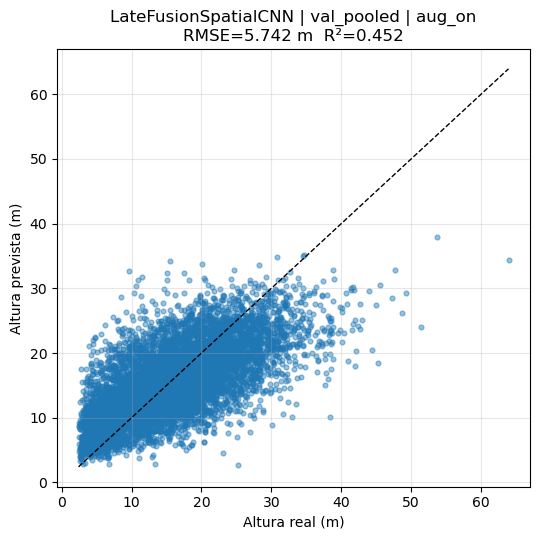

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\LateFusionSpatialCNN_val_pooled_aug_on_residuos.png


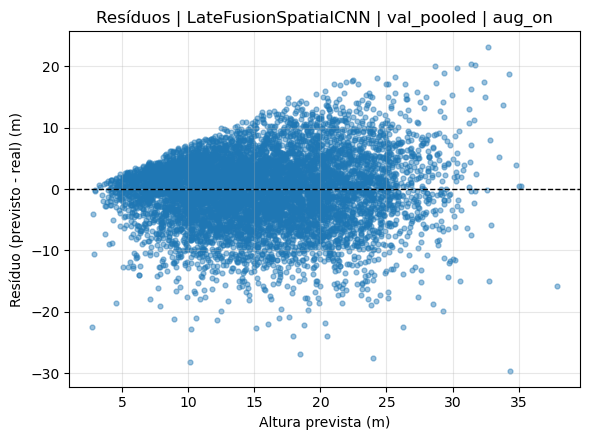

Histograma — aug_on | N real=7561 | N previsto=7561
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\hist_real_vs_previsto_aug_on.png


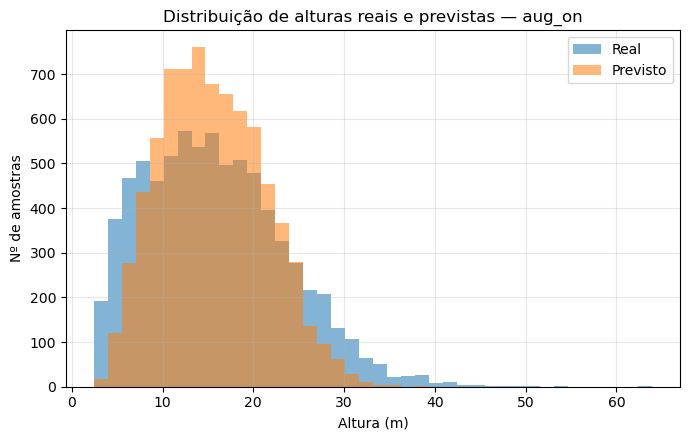

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\rmse_por_regiao_aug_on.png


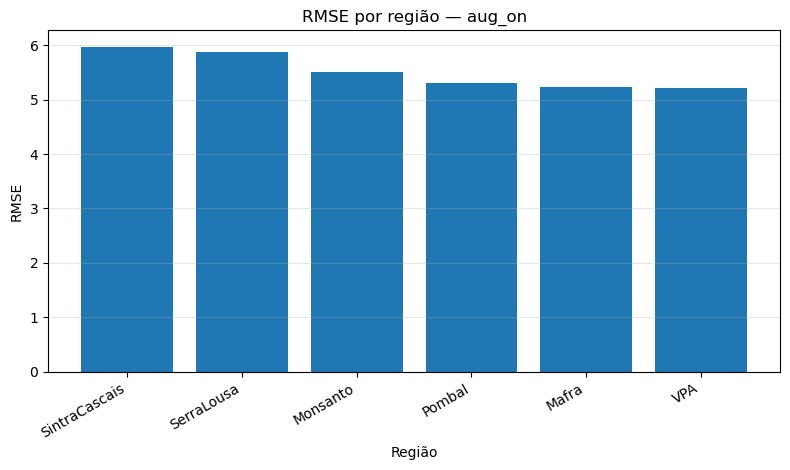

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\r2_por_regiao_aug_on.png


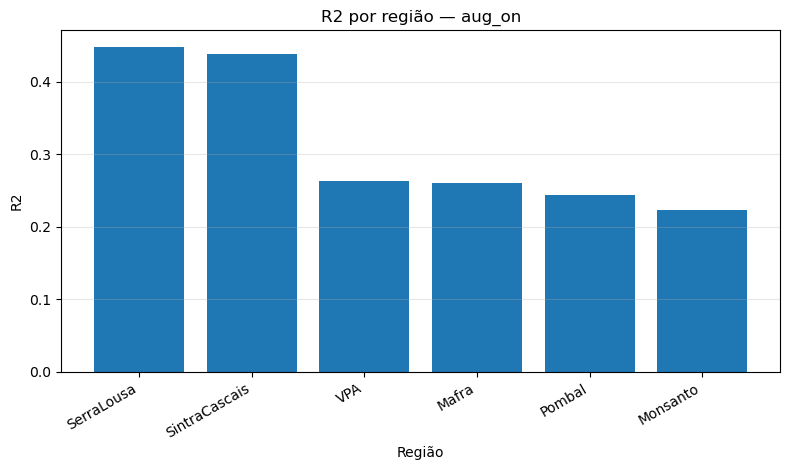

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\rmse_por_classe_altura_aug_on.png


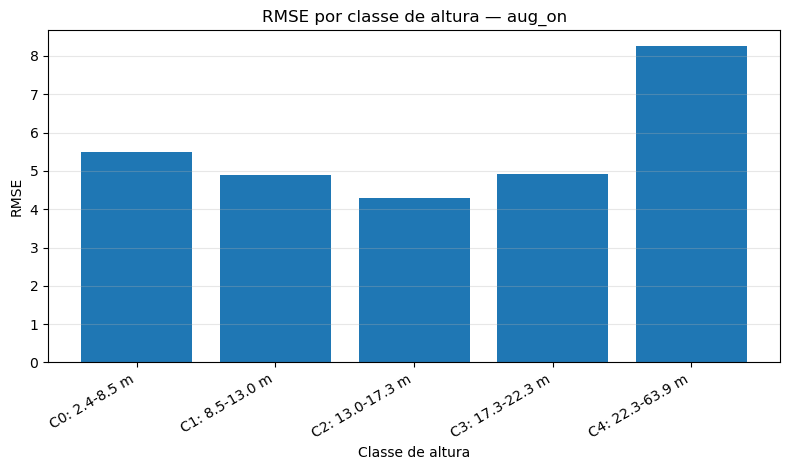

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\bias_por_classe_altura_aug_on.png


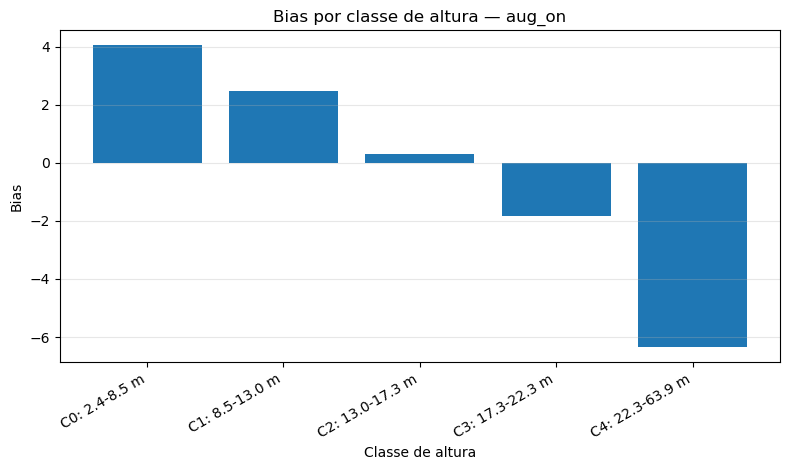

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\boxplot_residuos_por_regiao_aug_on.png

C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:209: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=regions, showfliers=False)


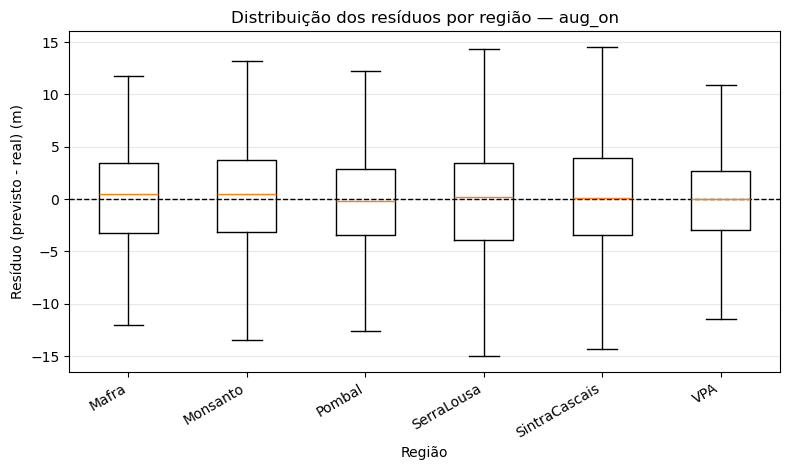

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\boxplot_residuos_por_classe_altura_aug_on.png


C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:191: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


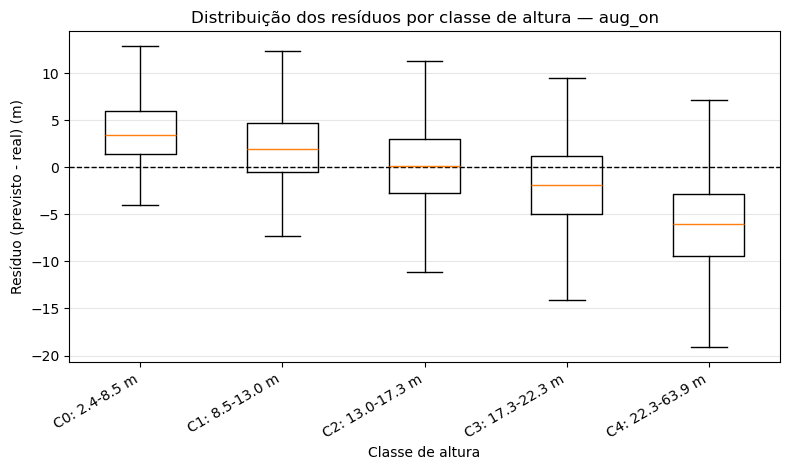

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\evolucao_media_val_rmse_aug_on.png


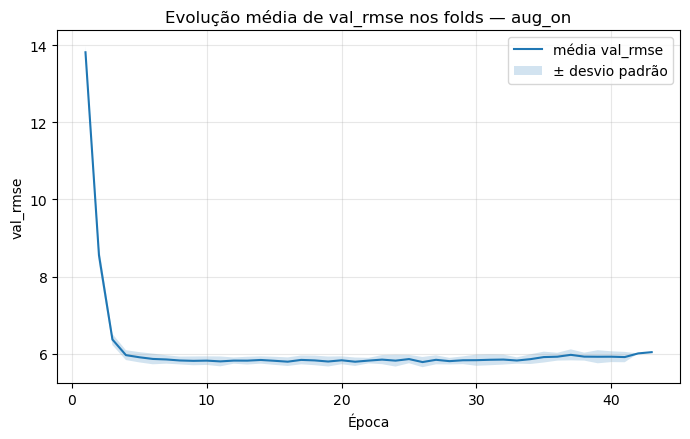

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3\figuras\evolucao_media_val_r2_aug_on.png


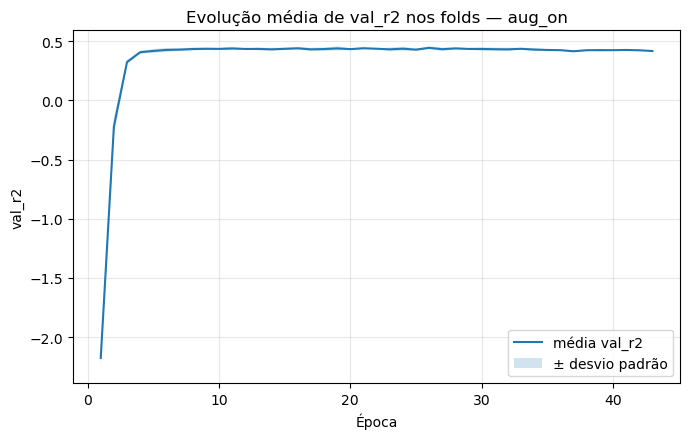


Resultados do patch 3x3 guardados em: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_3x3

 PIPELINE FCH — LateFusionSpatialCNN — PATCH 5x5
 CV: global misturado | estratificação: região + classe de altura
 Pasta de entrada: D:\Tese_data_refinada\_example_patches_by_size\patch_5x5
 Pasta de saída:   outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5
-> A ler TIFs e cruzar com GeoPackages...
   Pasta: D:\Tese_data_refinada\_example_patches_by_size\patch_5x5

Área: Mafra
   Bandas removidas (leakage): ['Mafra_20200000_CHM_AGBD_ALL', 'Mafra_20200000_CHM_BGBD_ALL', 'Mafra_20200000_CHM_LBD_ALL', 'Mafra_20200000_CHM_SBD_ALL']
   Área de referência para ordem das bandas.
   Carregados: 366 | Sem target: 0 | Fora da interseção comum: 82

Área: Monsanto
   Bandas removidas (leakage): ['Monsanto_20200000_CHM_AGBD_ALL', 'Monsanto_20200000_CHM_BGBD_ALL', 'Monsanto_20200000_CHM_LBD_ALL', 'Monsanto_20200000_CHM_SBD_ALL']
 

region,Mafra,Monsanto,Pombal,SerraLousa,SintraCascais,VPA
fold,,,,,,
1,74,78,152,1002,106,101
2,73,79,151,1003,106,100
3,73,79,151,1003,106,100
4,73,78,152,1003,106,100
5,73,78,152,1002,107,100



=== Distribuição de classes de altura por fold ===


height_class,0,1,2,3,4
fold,,,,,
1,303,303,302,303,302
2,301,303,304,301,303
3,302,301,304,301,304
4,305,303,300,303,301
5,303,302,302,304,301



=== Distribuição região × classe de altura por fold ===


region       Mafra                Monsanto                  ... SintraCascais  \
height_class     0   1   2   3  4        0   1   2   3   4  ...             0   
fold                                                        ...                 
1               27  21  11  11  4       12  19  19  18  10  ...            17   
2               27  21  11  11  3       12  19  20  18  10  ...            16   
3               27  20  11  11  4       12  19  20  17  11  ...            16   
4               27  21  10  11  4       13  19  19  17  10  ...            16   
5               26  21  11  11  4       12  19  19  18  10  ...            17   

region                       VPA                 
height_class   1   2   3   4   0   1   2   3  4  
fold                                             
1             15  27  25  22  43  25  17  10  6  
2             15  27  25  23  43  25  17   9  6  
3             15  27  25  23  44  24  17   9  6  
4             15  27  26  22  44  24  16  10  6  
5             15  27  26  22  44  24  16  10  6  

[5 rows x 30 columns]

... (11 outputs left out)

patch_size augmentation height_class      RMSE                %RMSE  \
                                            mean       std       mean   
0          5       aug_on            0  5.370822  0.286325  89.379366   
1          5       aug_on            1  4.790551  0.104622  44.097174   
2          5       aug_on            2  4.258033  0.266403  28.128846   
3          5       aug_on            3  4.924864  0.220209  25.024590   
4          5       aug_on            4  8.161439  0.594062  29.702455   

                  MAE                   R2                Bias            \
        std      mean       std       mean       std      mean       std   
0  4.408326  4.171883  0.217413 -10.390478  1.532477  3.933757  0.277759   
1  0.860641  3.617917  0.122709 -12.629423  0.730677  2.381390  0.208824   
2  1.785929  3.368903  0.149943 -11.165475  1.322206  0.227456  0.186907   
3  1.116956  4.008478  0.200130 -11.343493  1.732463 -1.884500  0.349995   
4  1.928364  6.687238  0.531855  -2.190789  0.107587 -6.206016  0.593387   

  Covariancia            
         mean       std  
0    1.751025  0.085442  
1    0.724574  0.241090  
2    0.647769  0.264376  
3    0.959355  0.380935  
4    7.441108  0.608738


=== Comparação direta da ablation augmentation ===


RMSE                %RMSE                 MAE  \
                             mean       std       mean       std      mean   
patch_size augmentation                                                      
5          aug_on        5.677257  0.139894  35.867524  0.738844  4.370777   

                                         R2                Bias            
                              std      mean       std      mean       std  
patch_size augmentation                                                    
5          aug_on        0.076309  0.463759  0.016292 -0.307942  0.210844


=== Gráficos finais — aug_on ===
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\LateFusionSpatialCNN_val_pooled_aug_on_real_vs_previsto.png


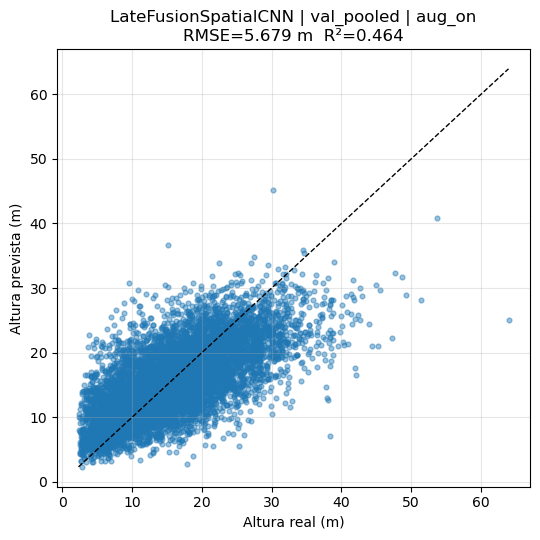

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\LateFusionSpatialCNN_val_pooled_aug_on_residuos.png


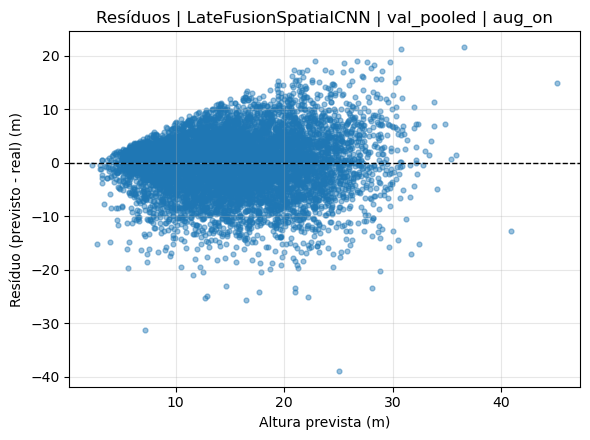

Histograma — aug_on | N real=7561 | N previsto=7561
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\hist_real_vs_previsto_aug_on.png


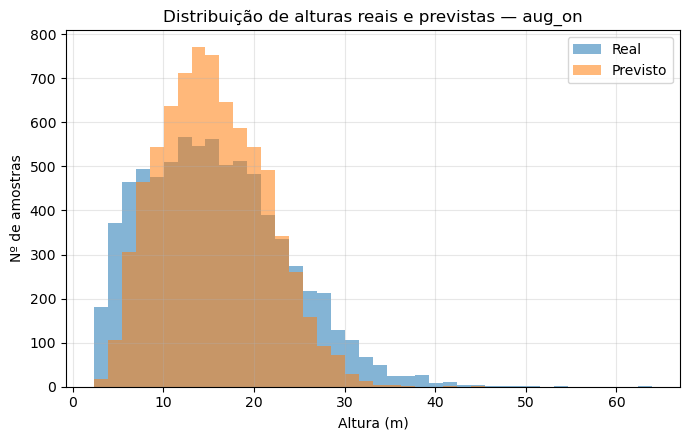

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\rmse_por_regiao_aug_on.png


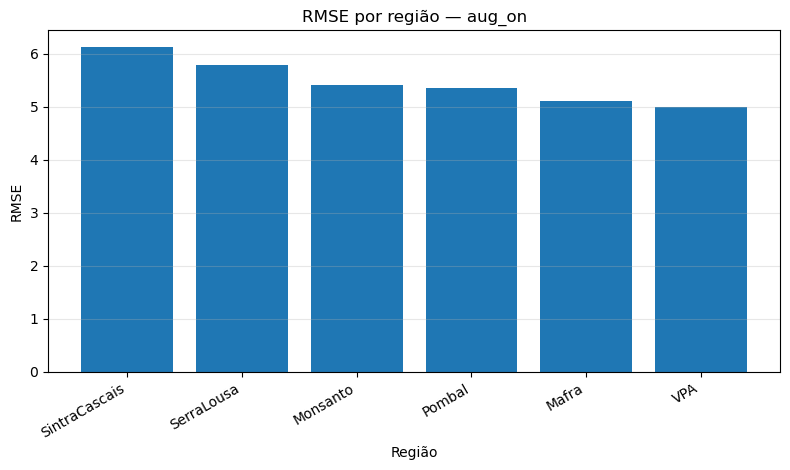

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\r2_por_regiao_aug_on.png


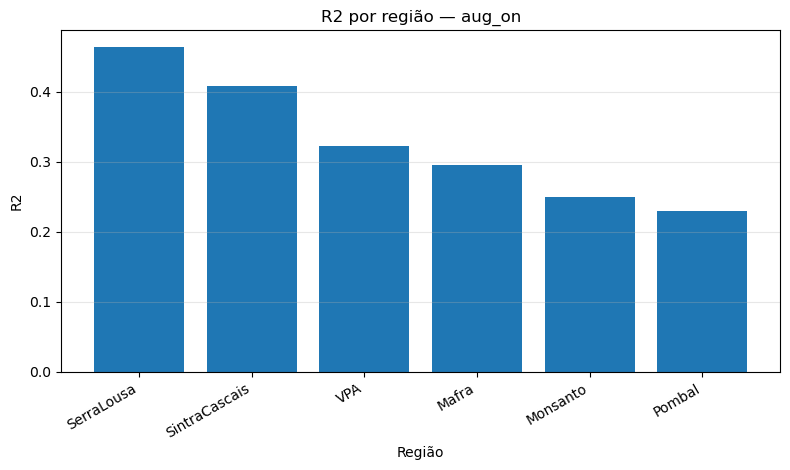

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\rmse_por_classe_altura_aug_on.png


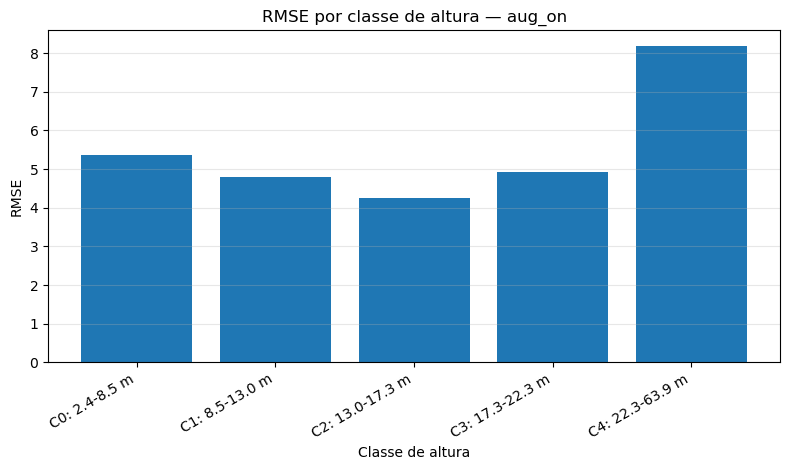

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\bias_por_classe_altura_aug_on.png


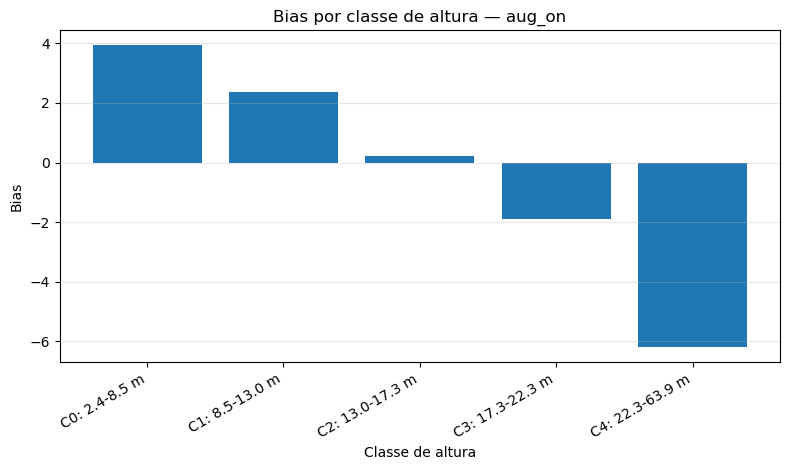

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\boxplot_residuos_por_regiao_aug_on.png


C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:209: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=regions, showfliers=False)


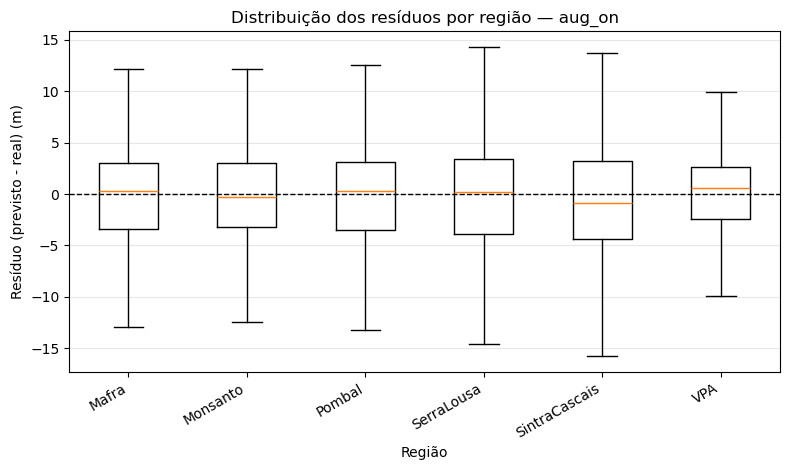

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\boxplot_residuos_por_classe_altura_aug_on.png


C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:191: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


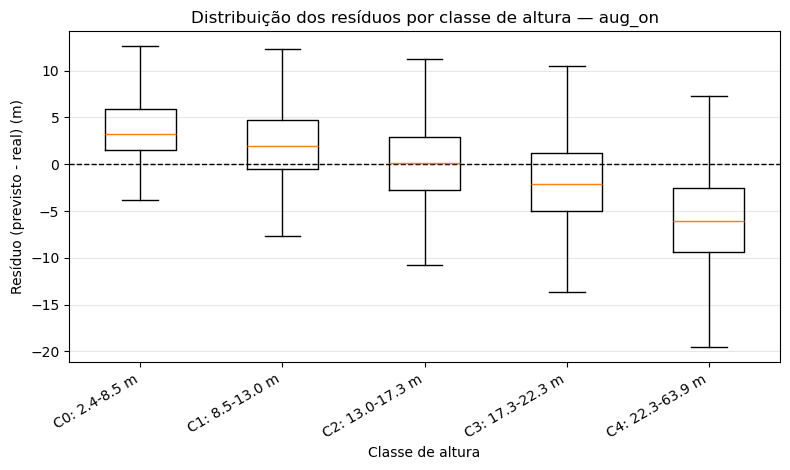

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\evolucao_media_val_rmse_aug_on.png


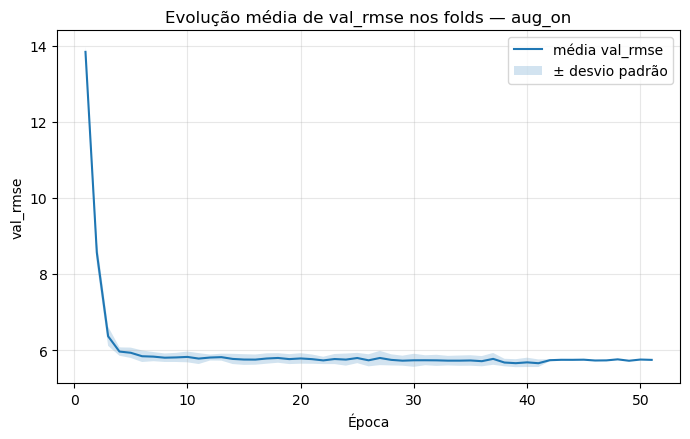

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5\figuras\evolucao_media_val_r2_aug_on.png


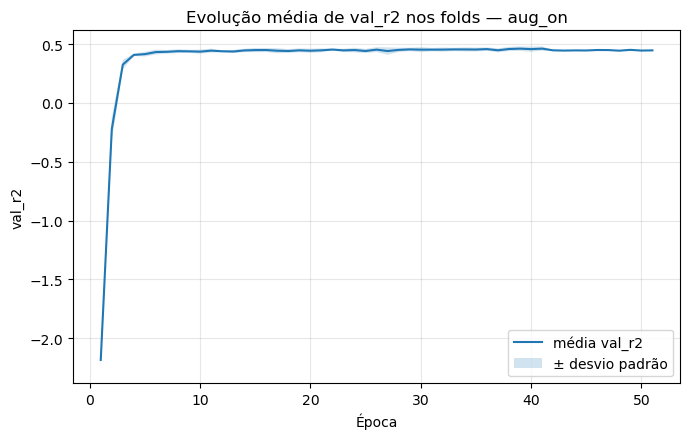


Resultados do patch 5x5 guardados em: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_5x5

 PIPELINE FCH — LateFusionSpatialCNN — PATCH 7x7
 CV: global misturado | estratificação: região + classe de altura
 Pasta de entrada: D:\Tese_data_refinada\_example_patches_by_size\patch_7x7
 Pasta de saída:   outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7
-> A ler TIFs e cruzar com GeoPackages...
   Pasta: D:\Tese_data_refinada\_example_patches_by_size\patch_7x7

Área: Mafra
   Bandas removidas (leakage): ['Mafra_20200000_CHM_AGBD_ALL', 'Mafra_20200000_CHM_BGBD_ALL', 'Mafra_20200000_CHM_LBD_ALL', 'Mafra_20200000_CHM_SBD_ALL']
   Área de referência para ordem das bandas.
   Carregados: 366 | Sem target: 0 | Fora da interseção comum: 70

Área: Monsanto
   Bandas removidas (leakage): ['Monsanto_20200000_CHM_AGBD_ALL', 'Monsanto_20200000_CHM_BGBD_ALL', 'Monsanto_20200000_CHM_LBD_ALL', 'Monsanto_20200000_CHM_SBD_ALL']
 

region,Mafra,Monsanto,Pombal,SerraLousa,SintraCascais,VPA
fold,,,,,,
1,74,78,152,1002,106,101
2,73,79,151,1003,106,100
3,73,79,151,1003,106,100
4,73,78,152,1003,106,100
5,73,78,152,1002,107,100



=== Distribuição de classes de altura por fold ===


height_class,0,1,2,3,4
fold,,,,,
1,303,303,302,303,302
2,301,303,304,301,303
3,302,301,304,301,304
4,305,303,300,303,301
5,303,302,302,304,301



=== Distribuição região × classe de altura por fold ===


region       Mafra                Monsanto                  ... SintraCascais  \
height_class     0   1   2   3  4        0   1   2   3   4  ...             0   
fold                                                        ...                 
1               27  21  11  11  4       12  19  19  18  10  ...            17   
2               27  21  11  11  3       12  19  20  18  10  ...            16   
3               27  20  11  11  4       12  19  20  17  11  ...            16   
4               27  21  10  11  4       13  19  19  17  10  ...            16   
5               26  21  11  11  4       12  19  19  18  10  ...            17   

region                       VPA                 
height_class   1   2   3   4   0   1   2   3  4  
fold                                             
1             15  27  25  22  43  25  17  10  6  
2             15  27  25  23  43  25  17   9  6  
3             15  27  25  23  44  24  17   9  6  
4             15  27  26  22  44  24  16  10  6  
5             15  27  26  22  44  24  16  10  6  

[5 rows x 30 columns]

... (11 outputs left out)

patch_size augmentation height_class      RMSE                %RMSE  \
                                            mean       std       mean   
0          7       aug_on            0  5.408503  0.257394  89.997748   
1          7       aug_on            1  4.813697  0.115795  44.312310   
2          7       aug_on            2  4.232085  0.174083  27.959658   
3          7       aug_on            3  4.873383  0.232197  24.762876   
4          7       aug_on            4  7.926722  0.287052  28.855313   

                  MAE                   R2                Bias            \
        std      mean       std       mean       std      mean       std   
0  3.625518  4.168756  0.219281 -10.558991  1.573850  3.905437  0.233916   
1  1.081183  3.608363  0.096742 -12.762284  0.763326  2.363918  0.243702   
2  1.255570  3.322304  0.109992 -11.026963  1.187996  0.118546  0.168448   
3  1.174909  3.954039  0.229671 -11.079272  1.619164 -1.802723  0.153337   
4  0.866749  6.504723  0.175243  -2.027773  0.272782 -5.872495  0.246986   

  Covariancia            
         mean       std  
0    1.633877  0.458989  
1    0.686454  0.193705  
2    0.716493  0.221304  
3    0.862406  0.384781  
4    8.956146  0.513751


=== Comparação direta da ablation augmentation ===


RMSE                %RMSE                 MAE  \
                            mean       std       mean       std      mean   
patch_size augmentation                                                     
7          aug_on        5.60497  0.082868  35.412171  0.405113  4.311469   

                                         R2                Bias            
                              std      mean       std      mean       std  
patch_size augmentation                                                    
7          aug_on        0.050195  0.477319  0.007527 -0.255904  0.051489


=== Gráficos finais — aug_on ===
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\LateFusionSpatialCNN_val_pooled_aug_on_real_vs_previsto.png


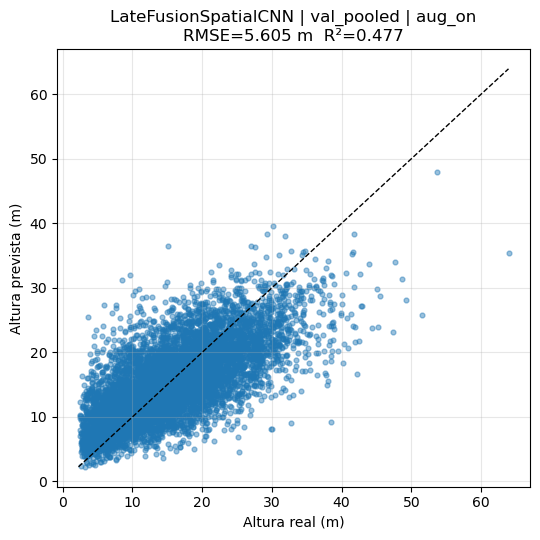

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\LateFusionSpatialCNN_val_pooled_aug_on_residuos.png


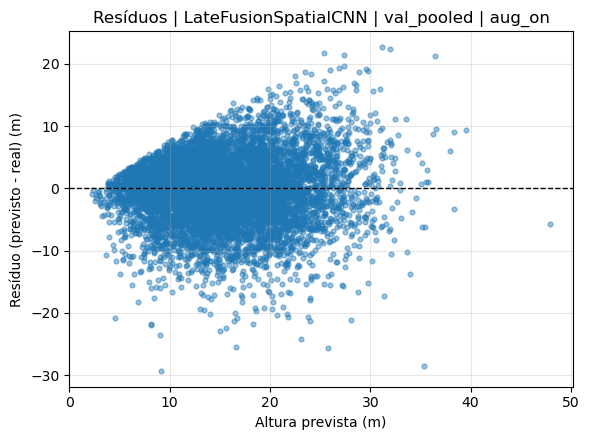

Histograma — aug_on | N real=7561 | N previsto=7561
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\hist_real_vs_previsto_aug_on.png


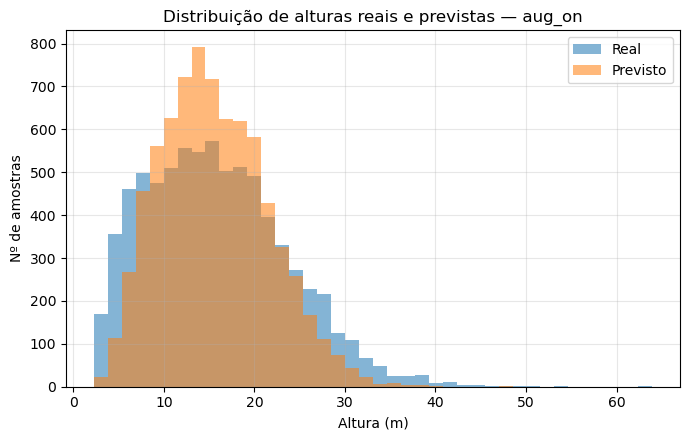

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\rmse_por_regiao_aug_on.png


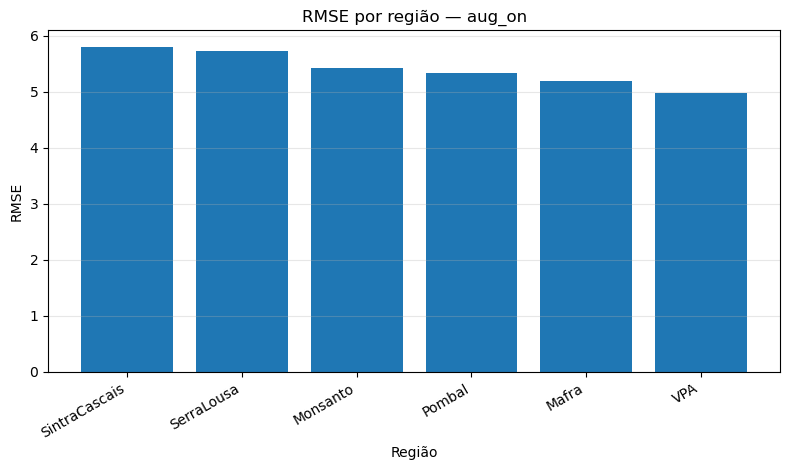

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\r2_por_regiao_aug_on.png


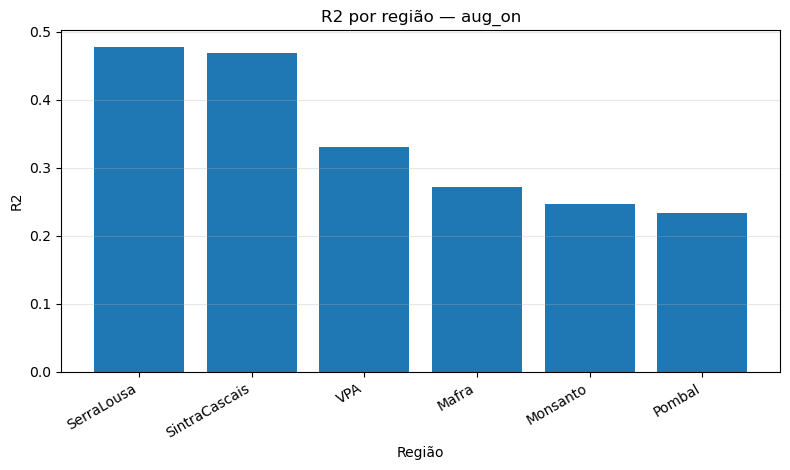

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\rmse_por_classe_altura_aug_on.png


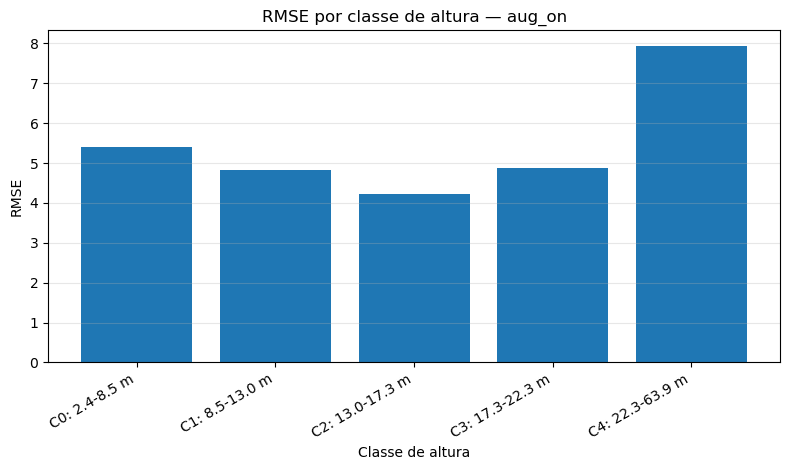

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\bias_por_classe_altura_aug_on.png


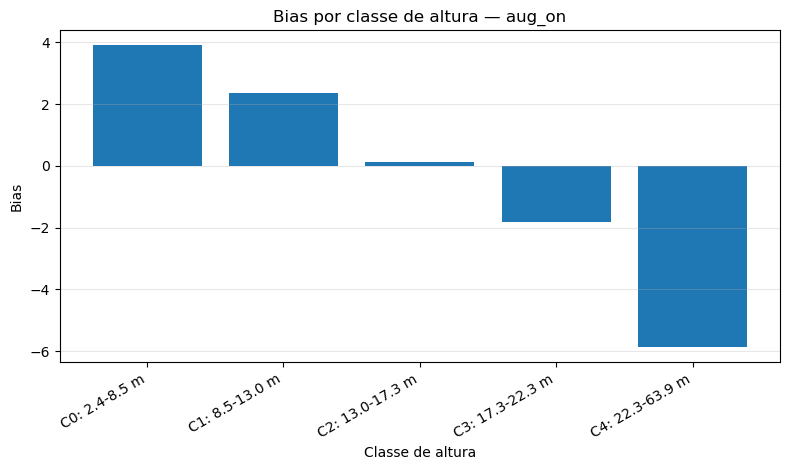

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\boxplot_residuos_por_regiao_aug_on.png


C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:209: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=regions, showfliers=False)


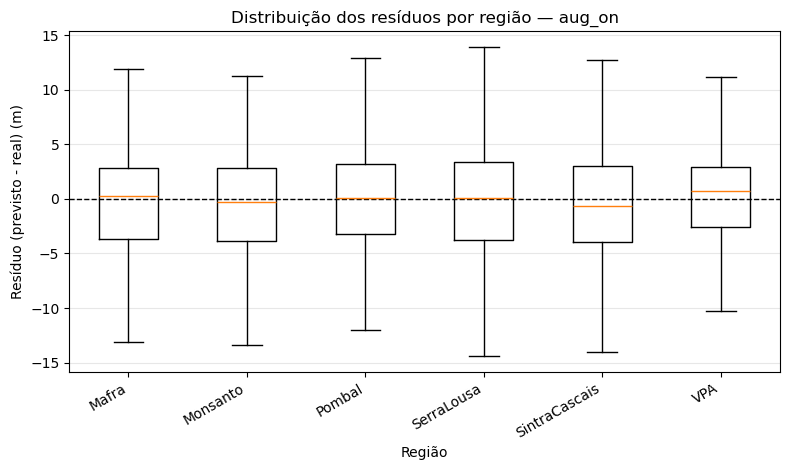

C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:191: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\boxplot_residuos_por_classe_altura_aug_on.png


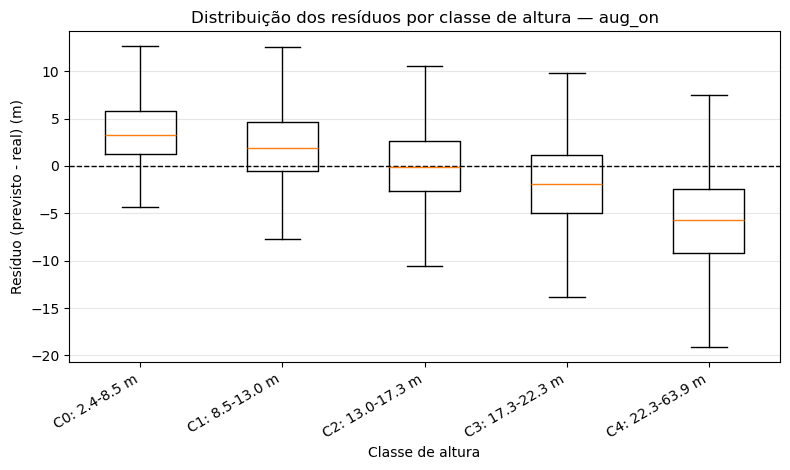

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\evolucao_media_val_rmse_aug_on.png


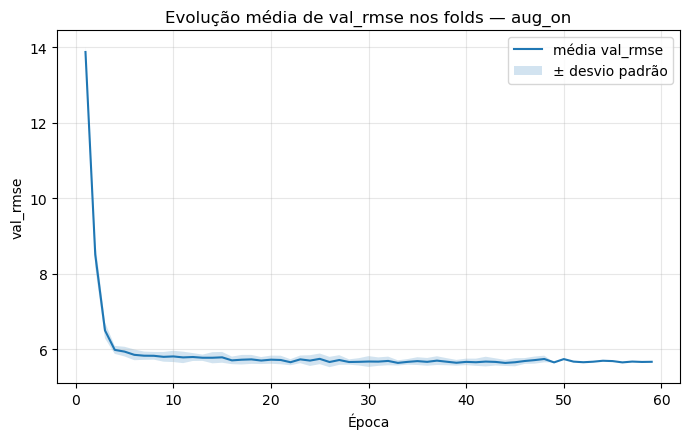

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7\figuras\evolucao_media_val_r2_aug_on.png


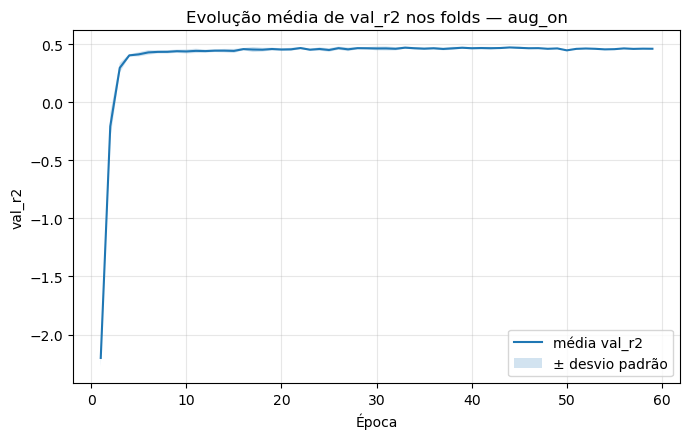


Resultados do patch 7x7 guardados em: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_7x7

 PIPELINE FCH — LateFusionSpatialCNN — PATCH 11x11
 CV: global misturado | estratificação: região + classe de altura
 Pasta de entrada: D:\Tese_data_refinada\_example_patches_by_size\patch_11x11
 Pasta de saída:   outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11
-> A ler TIFs e cruzar com GeoPackages...
   Pasta: D:\Tese_data_refinada\_example_patches_by_size\patch_11x11

Área: Mafra
   Bandas removidas (leakage): ['Mafra_20200000_CHM_AGBD_ALL', 'Mafra_20200000_CHM_BGBD_ALL', 'Mafra_20200000_CHM_LBD_ALL', 'Mafra_20200000_CHM_SBD_ALL']
   Área de referência para ordem das bandas.
   Carregados: 366 | Sem target: 0 | Fora da interseção comum: 48

Área: Monsanto
   Bandas removidas (leakage): ['Monsanto_20200000_CHM_AGBD_ALL', 'Monsanto_20200000_CHM_BGBD_ALL', 'Monsanto_20200000_CHM_LBD_ALL', 'Monsanto_20200000_CHM_SBD

region,Mafra,Monsanto,Pombal,SerraLousa,SintraCascais,VPA
fold,,,,,,
1,74,78,152,1002,106,101
2,73,79,151,1003,106,100
3,73,79,151,1003,106,100
4,73,78,152,1003,106,100
5,73,78,152,1002,107,100



=== Distribuição de classes de altura por fold ===


height_class,0,1,2,3,4
fold,,,,,
1,303,303,302,303,302
2,301,303,304,301,303
3,302,301,304,301,304
4,305,303,300,303,301
5,303,302,302,304,301



=== Distribuição região × classe de altura por fold ===


region       Mafra                Monsanto                  ... SintraCascais  \
height_class     0   1   2   3  4        0   1   2   3   4  ...             0   
fold                                                        ...                 
1               27  21  11  11  4       12  19  19  18  10  ...            17   
2               27  21  11  11  3       12  19  20  18  10  ...            16   
3               27  20  11  11  4       12  19  20  17  11  ...            16   
4               27  21  10  11  4       13  19  19  17  10  ...            16   
5               26  21  11  11  4       12  19  19  18  10  ...            17   

region                       VPA                 
height_class   1   2   3   4   0   1   2   3  4  
fold                                             
1             15  27  25  22  43  25  17  10  6  
2             15  27  25  23  43  25  17   9  6  
3             15  27  25  23  44  24  17   9  6  
4             15  27  26  22  44  24  16  10  6  
5             15  27  26  22  44  24  16  10  6  

[5 rows x 30 columns]

... (11 outputs left out)

patch_size augmentation height_class      RMSE                %RMSE  \
                                            mean       std       mean   
0         11       aug_on            0  5.355552  0.334070  89.107980   
1         11       aug_on            1  4.671767  0.207945  43.009151   
2         11       aug_on            2  4.311542  0.169294  28.484870   
3         11       aug_on            3  4.829444  0.299801  24.539909   
4         11       aug_on            4  7.881051  0.199956  28.691675   

                  MAE                   R2                Bias            \
        std      mean       std       mean       std      mean       std   
0  4.893667  4.148326  0.253208 -10.361050  1.888978  3.858655  0.291076   
1  2.009915  3.512960  0.153270 -11.984060  1.300365  2.164291  0.226131   
2  1.237875  3.401720  0.117672 -11.484349  1.226724  0.136266  0.208456   
3  1.526207  3.899517  0.284094 -10.881185  1.884504 -1.741707  0.185872   
4  0.624348  6.410705  0.155209  -2.000256  0.331295 -5.746809  0.206042   

  Covariancia            
         mean       std  
0    1.599274  0.293142  
1    0.702037  0.284719  
2    0.794967  0.306565  
3    1.104462  0.422972  
4    8.666757  1.255405


=== Comparação direta da ablation augmentation ===


RMSE                %RMSE                 MAE  \
                             mean       std       mean       std      mean   
patch_size augmentation                                                      
11         aug_on        5.563309  0.077209  35.149905  0.462144  4.274519   

                                         R2               Bias            
                              std      mean       std     mean       std  
patch_size augmentation                                                   
11         aug_on        0.076047  0.484962  0.013011 -0.26428  0.104203


=== Gráficos finais — aug_on ===
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\LateFusionSpatialCNN_val_pooled_aug_on_real_vs_previsto.png


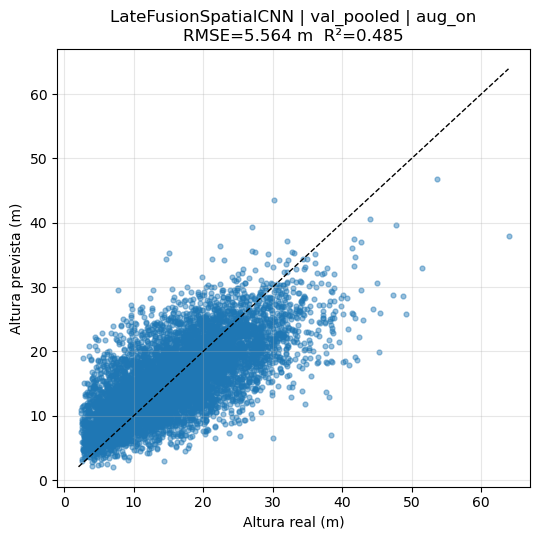

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\LateFusionSpatialCNN_val_pooled_aug_on_residuos.png


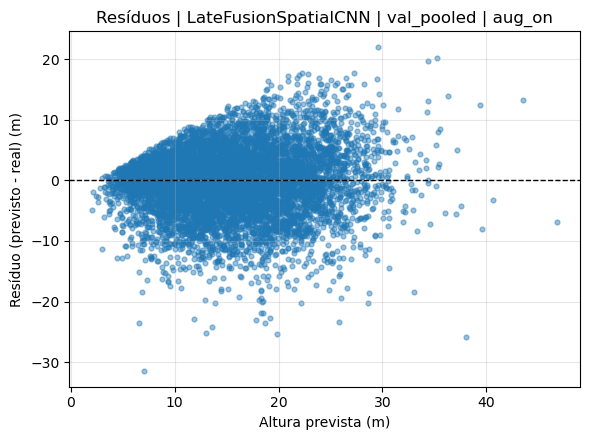

Histograma — aug_on | N real=7561 | N previsto=7561
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\hist_real_vs_previsto_aug_on.png


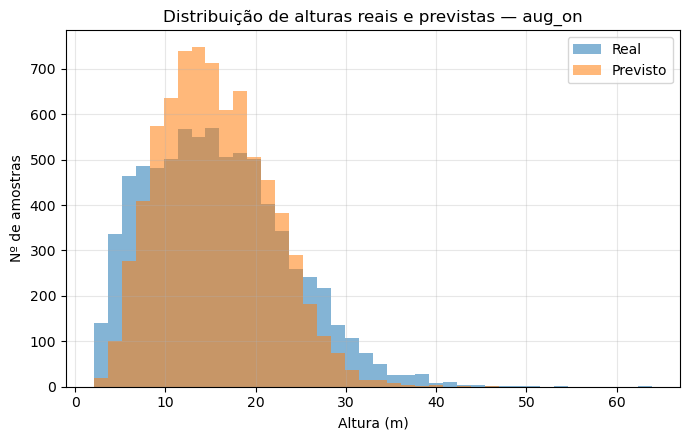

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\rmse_por_regiao_aug_on.png


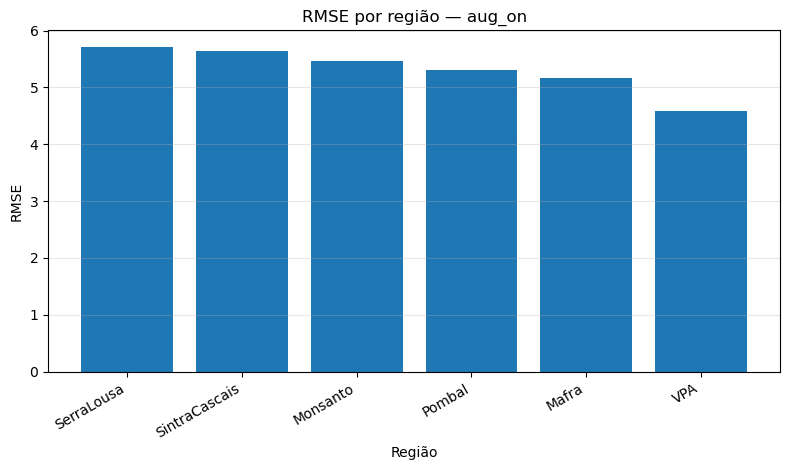

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\r2_por_regiao_aug_on.png


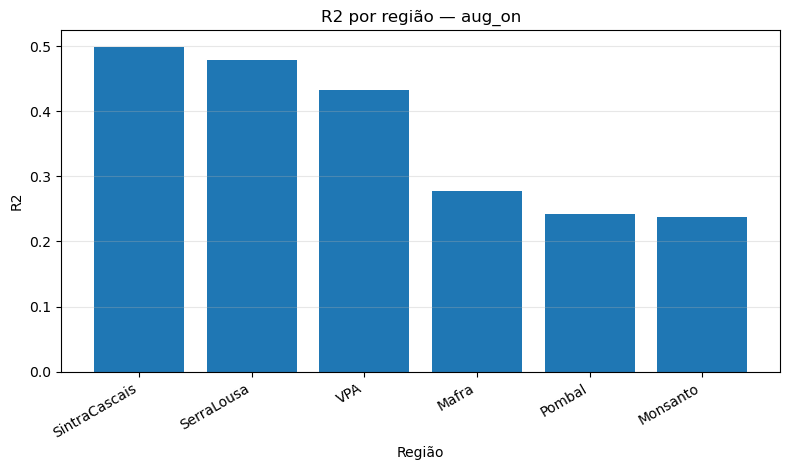

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\rmse_por_classe_altura_aug_on.png


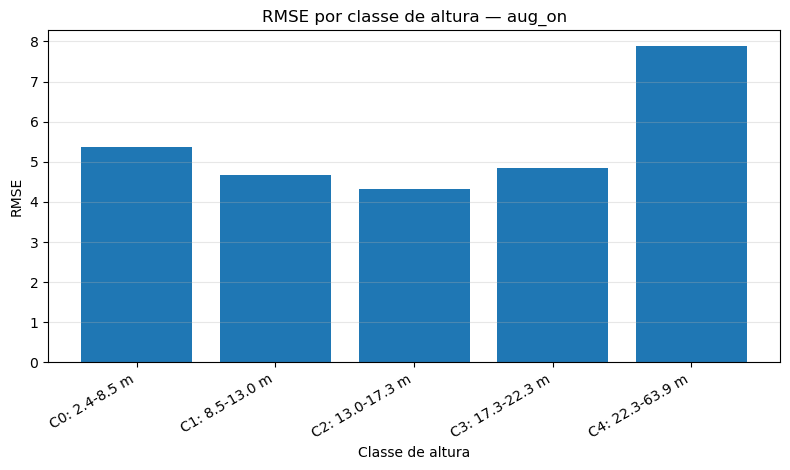

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\bias_por_classe_altura_aug_on.png


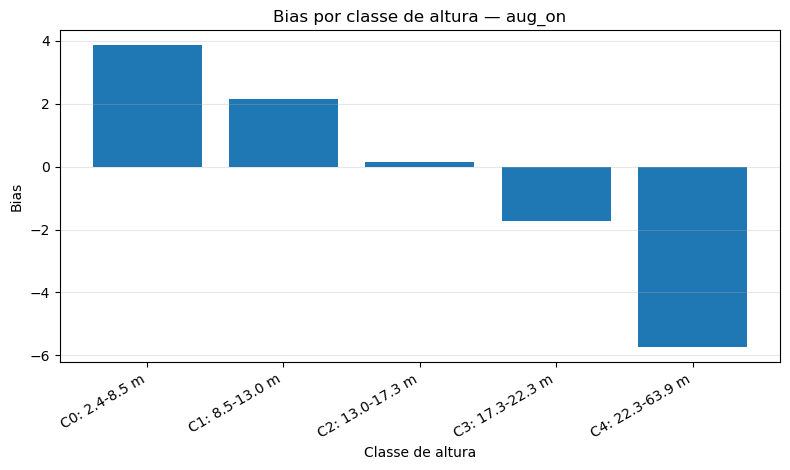

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\boxplot_residuos_por_regiao_aug_on.png


C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:209: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=regions, showfliers=False)


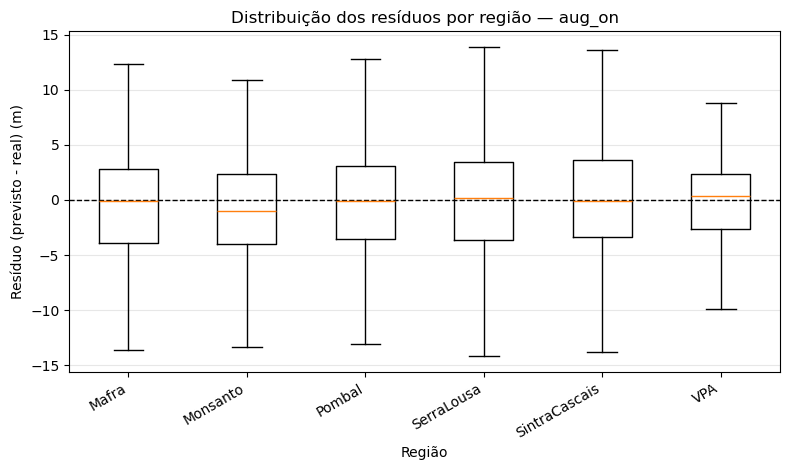

C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:191: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\boxplot_residuos_por_classe_altura_aug_on.png


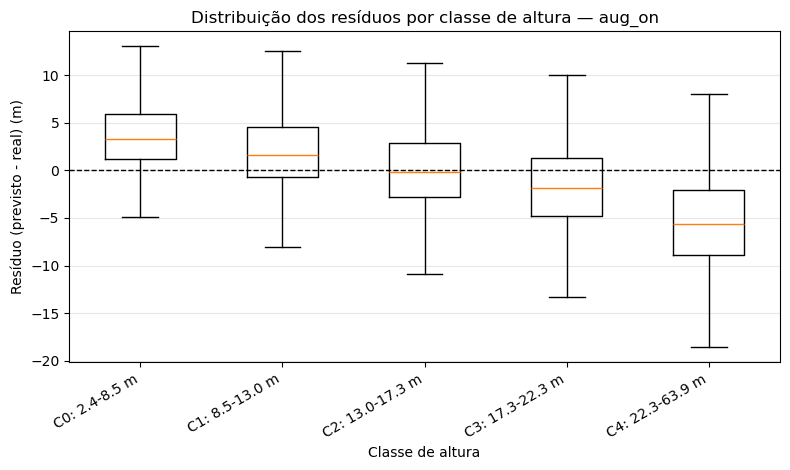

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\evolucao_media_val_rmse_aug_on.png


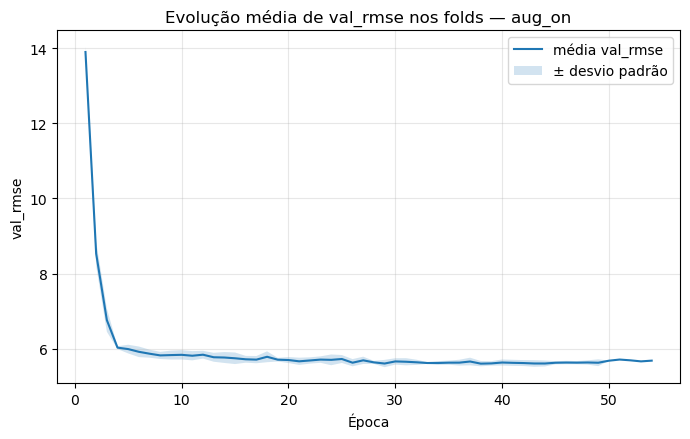

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11\figuras\evolucao_media_val_r2_aug_on.png


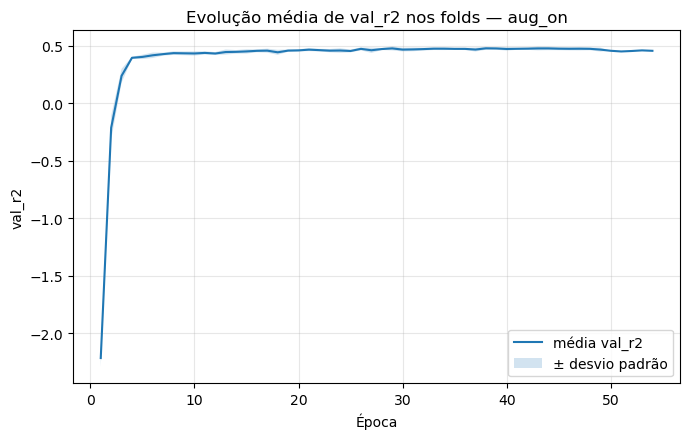


Resultados do patch 11x11 guardados em: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_11x11

 PIPELINE FCH — LateFusionSpatialCNN — PATCH 15x15
 CV: global misturado | estratificação: região + classe de altura
 Pasta de entrada: D:\Tese_data_refinada\_example_patches_by_size\patch_15x15
 Pasta de saída:   outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15
-> A ler TIFs e cruzar com GeoPackages...
   Pasta: D:\Tese_data_refinada\_example_patches_by_size\patch_15x15

Área: Mafra
   Bandas removidas (leakage): ['Mafra_20200000_CHM_AGBD_ALL', 'Mafra_20200000_CHM_BGBD_ALL', 'Mafra_20200000_CHM_LBD_ALL', 'Mafra_20200000_CHM_SBD_ALL']
   Área de referência para ordem das bandas.
   Carregados: 366 | Sem target: 0 | Fora da interseção comum: 23

Área: Monsanto
   Bandas removidas (leakage): ['Monsanto_20200000_CHM_AGBD_ALL', 'Monsanto_20200000_CHM_BGBD_ALL', 'Monsanto_20200000_CHM_LBD_ALL', 'Monsanto_20200000_CHM

region,Mafra,Monsanto,Pombal,SerraLousa,SintraCascais,VPA
fold,,,,,,
1,74,78,152,1002,106,101
2,73,79,151,1003,106,100
3,73,79,151,1003,106,100
4,73,78,152,1003,106,100
5,73,78,152,1002,107,100



=== Distribuição de classes de altura por fold ===


height_class,0,1,2,3,4
fold,,,,,
1,303,303,302,303,302
2,301,303,304,301,303
3,302,301,304,301,304
4,305,303,300,303,301
5,303,302,302,304,301



=== Distribuição região × classe de altura por fold ===


region       Mafra                Monsanto                  ... SintraCascais  \
height_class     0   1   2   3  4        0   1   2   3   4  ...             0   
fold                                                        ...                 
1               27  21  11  11  4       12  19  19  18  10  ...            17   
2               27  21  11  11  3       12  19  20  18  10  ...            16   
3               27  20  11  11  4       12  19  20  17  11  ...            16   
4               27  21  10  11  4       13  19  19  17  10  ...            16   
5               26  21  11  11  4       12  19  19  18  10  ...            17   

region                       VPA                 
height_class   1   2   3   4   0   1   2   3  4  
fold                                             
1             15  27  25  22  43  25  17  10  6  
2             15  27  25  23  43  25  17   9  6  
3             15  27  25  23  44  24  17   9  6  
4             15  27  26  22  44  24  16  10  6  
5             15  27  26  22  44  24  16  10  6  

[5 rows x 30 columns]

... (11 outputs left out)

patch_size augmentation height_class      RMSE                %RMSE  \
                                            mean       std       mean   
0         15       aug_on            0  5.594444  0.356573  93.080307   
1         15       aug_on            1  4.668368  0.340302  42.979492   
2         15       aug_on            2  4.223802  0.187852  27.904034   
3         15       aug_on            3  4.706047  0.277314  23.912509   
4         15       aug_on            4  7.853198  0.165890  28.590794   

                  MAE                   R2                Bias            \
        std      mean       std       mean       std      mean       std   
0  5.202943  4.400616  0.233386 -11.398483  2.074481  4.130929  0.168372   
1  3.214979  3.525257  0.264365 -12.016890  2.122608  2.253621  0.402865   
2  1.312729  3.315552  0.124704 -10.994035  1.393834  0.181870  0.233860   
3  1.404508  3.802205  0.244460 -10.270947  1.680863 -1.617082  0.224887   
4  0.512891  6.419481  0.076947  -1.980240  0.334176 -5.768260  0.288746   

  Covariancia            
         mean       std  
0    1.548482  0.314924  
1    0.666395  0.348124  
2    0.894539  0.251173  
3    1.052153  0.368046  
4    9.164676  1.136560


=== Comparação direta da ablation augmentation ===


RMSE                %RMSE                MAE  \
                             mean       std       mean       std     mean   
patch_size augmentation                                                     
15         aug_on        5.568478  0.064827  35.182224  0.336143  4.29266   

                                       R2                Bias            
                            std      mean       std      mean       std  
patch_size augmentation                                                  
15         aug_on        0.0573  0.484054  0.008666 -0.161954  0.193003


=== Gráficos finais — aug_on ===
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\LateFusionSpatialCNN_val_pooled_aug_on_real_vs_previsto.png


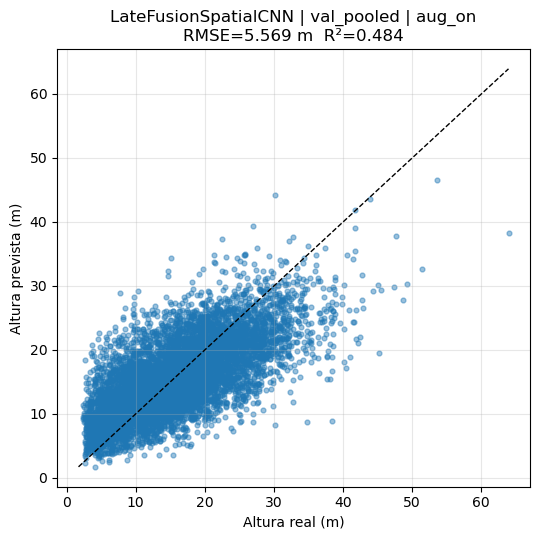

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\LateFusionSpatialCNN_val_pooled_aug_on_residuos.png


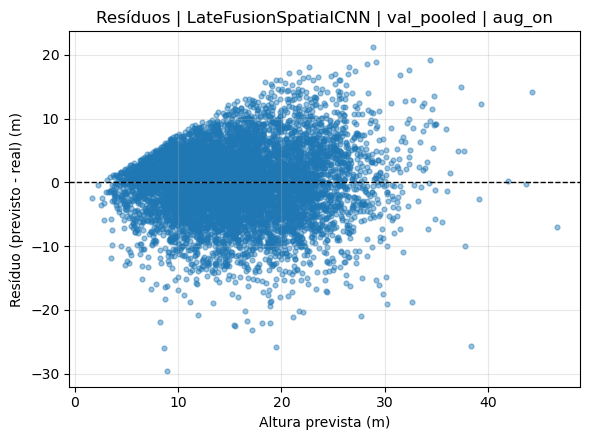

Histograma — aug_on | N real=7561 | N previsto=7561
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\hist_real_vs_previsto_aug_on.png


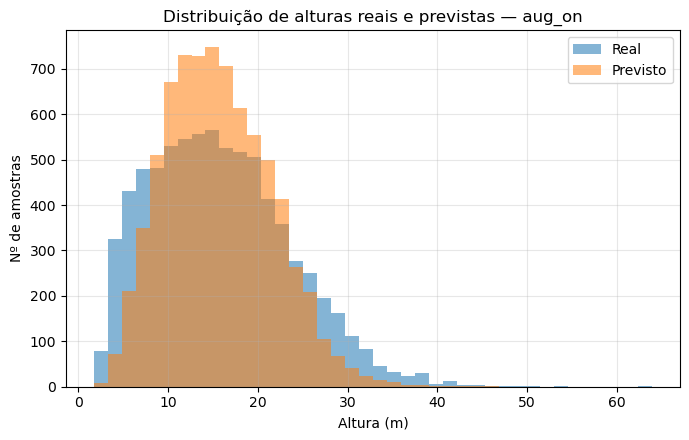

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\rmse_por_regiao_aug_on.png


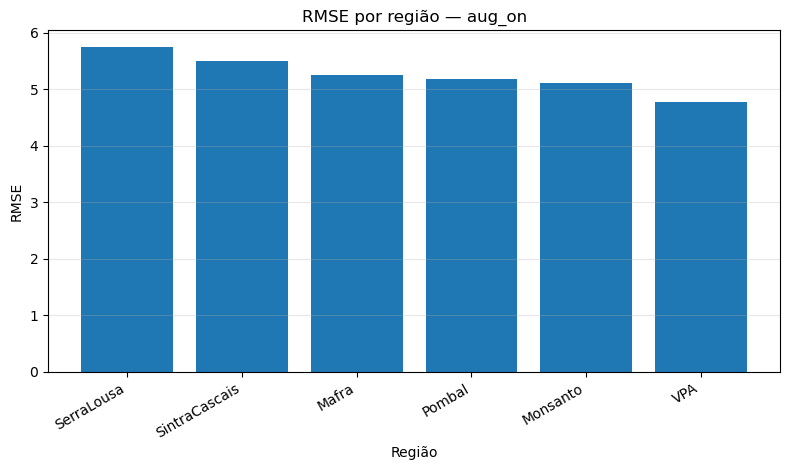

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\r2_por_regiao_aug_on.png


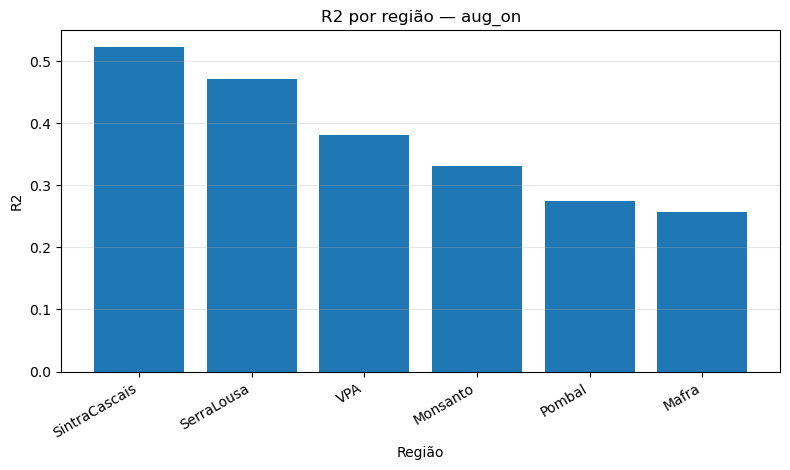

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\rmse_por_classe_altura_aug_on.png


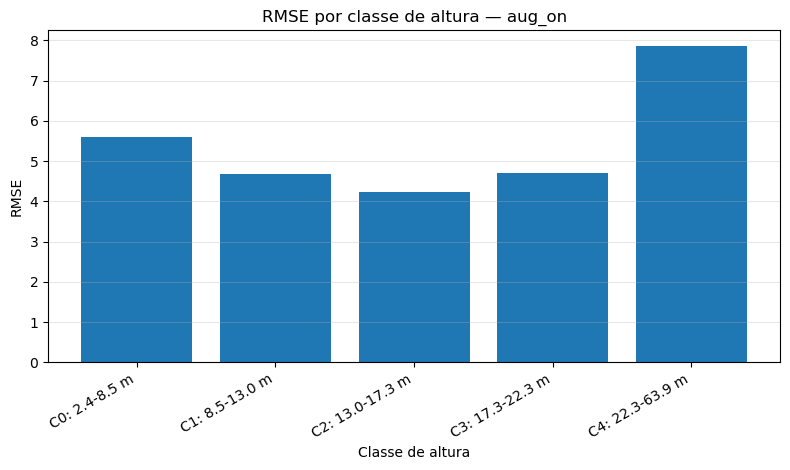

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\bias_por_classe_altura_aug_on.png


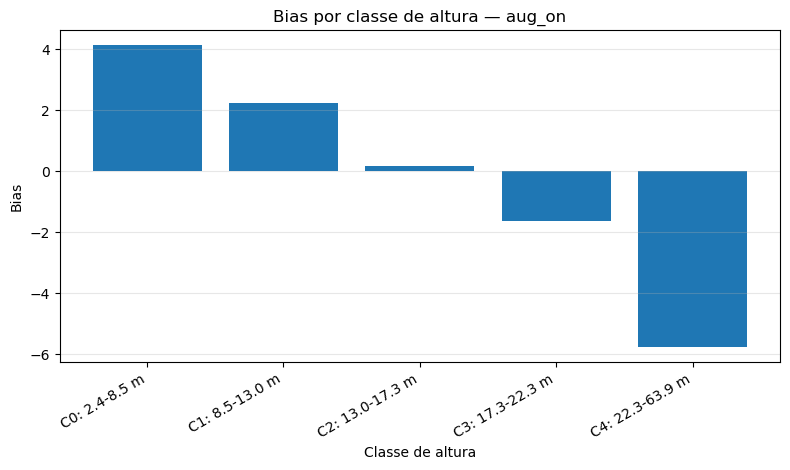

C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:209: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=regions, showfliers=False)


Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\boxplot_residuos_por_regiao_aug_on.png


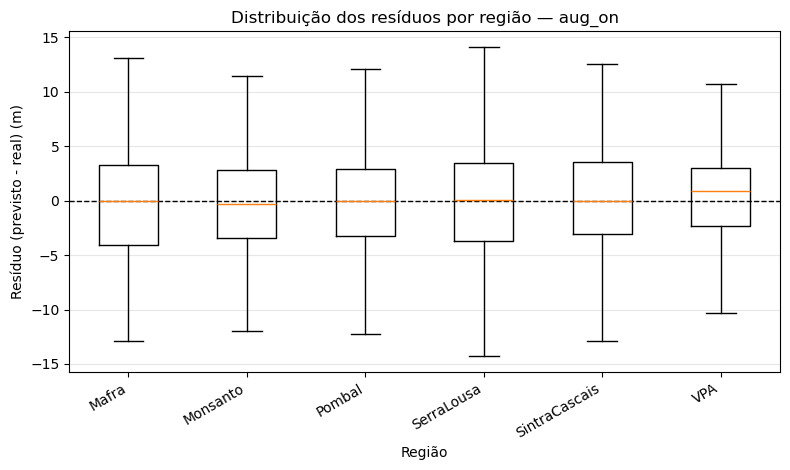

C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:191: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\boxplot_residuos_por_classe_altura_aug_on.png


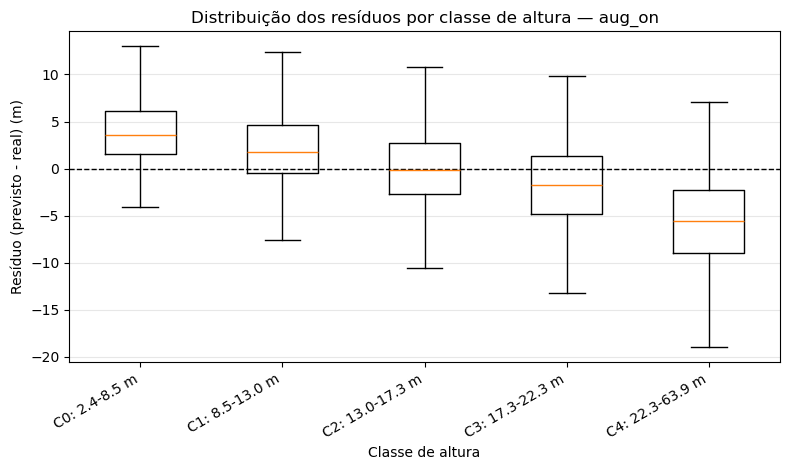

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\evolucao_media_val_rmse_aug_on.png


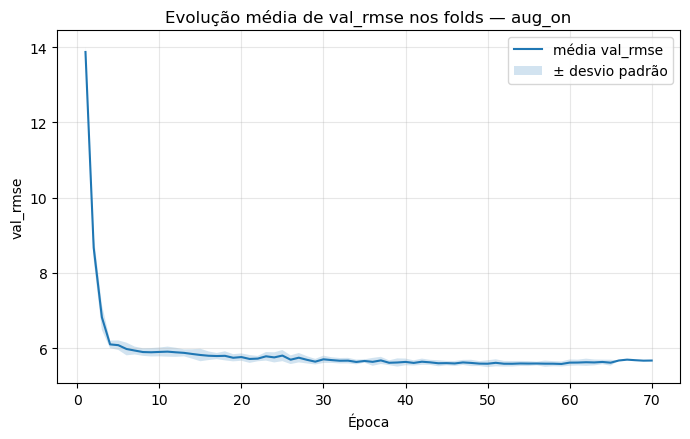

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15\figuras\evolucao_media_val_r2_aug_on.png


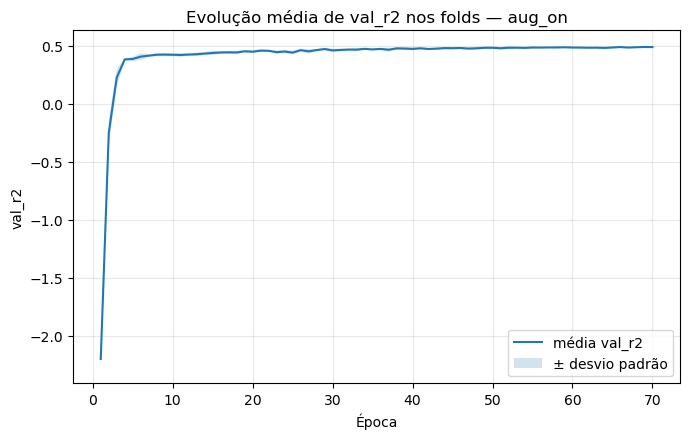


Resultados do patch 15x15 guardados em: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_15x15

 PIPELINE FCH — LateFusionSpatialCNN — PATCH 21x21
 CV: global misturado | estratificação: região + classe de altura
 Pasta de entrada: D:\Tese_data_refinada\_example_patches_by_size\patch_21x21
 Pasta de saída:   outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21
-> A ler TIFs e cruzar com GeoPackages...
   Pasta: D:\Tese_data_refinada\_example_patches_by_size\patch_21x21

Área: Mafra
   Bandas removidas (leakage): ['Mafra_20200000_CHM_AGBD_ALL', 'Mafra_20200000_CHM_BGBD_ALL', 'Mafra_20200000_CHM_LBD_ALL', 'Mafra_20200000_CHM_SBD_ALL']
   Área de referência para ordem das bandas.
   Carregados: 366 | Sem target: 0 | Fora da interseção comum: 10

Área: Monsanto
   Bandas removidas (leakage): ['Monsanto_20200000_CHM_AGBD_ALL', 'Monsanto_20200000_CHM_BGBD_ALL', 'Monsanto_20200000_CHM_LBD_ALL', 'Monsanto_20200000_CHM

region,Mafra,Monsanto,Pombal,SerraLousa,SintraCascais,VPA
fold,,,,,,
1,74,78,152,1002,106,101
2,73,79,151,1003,106,100
3,73,79,151,1003,106,100
4,73,78,152,1003,106,100
5,73,78,152,1002,107,100



=== Distribuição de classes de altura por fold ===


height_class,0,1,2,3,4
fold,,,,,
1,303,303,302,303,302
2,301,303,304,301,303
3,302,301,304,301,304
4,305,303,300,303,301
5,303,302,302,304,301



=== Distribuição região × classe de altura por fold ===


region       Mafra                Monsanto                  ... SintraCascais  \
height_class     0   1   2   3  4        0   1   2   3   4  ...             0   
fold                                                        ...                 
1               27  21  11  11  4       12  19  19  18  10  ...            17   
2               27  21  11  11  3       12  19  20  18  10  ...            16   
3               27  20  11  11  4       12  19  20  17  11  ...            16   
4               27  21  10  11  4       13  19  19  17  10  ...            16   
5               26  21  11  11  4       12  19  19  18  10  ...            17   

region                       VPA                 
height_class   1   2   3   4   0   1   2   3  4  
fold                                             
1             15  27  25  22  43  25  17  10  6  
2             15  27  25  23  43  25  17   9  6  
3             15  27  25  23  44  24  17   9  6  
4             15  27  26  22  44  24  16  10  6  
5             15  27  26  22  44  24  16  10  6  

[5 rows x 30 columns]

... (11 outputs left out)

patch_size augmentation height_class      RMSE                %RMSE  \
                                            mean       std       mean   
0         21       aug_on            0  5.737752  0.460489  95.465997   
1         21       aug_on            1  4.646159  0.192604  42.767789   
2         21       aug_on            2  4.190039  0.049005  27.678338   
3         21       aug_on            3  4.807499  0.258139  24.428421   
4         21       aug_on            4  7.976268  0.203963  29.038027   

                  MAE                   R2                Bias            \
        std      mean       std       mean       std      mean       std   
0  7.103202  4.550706  0.318927 -12.083186  2.696642  4.315143  0.289261   
1  1.705544  3.478433  0.173308 -11.830919  1.105916  2.251273  0.336596   
2  0.312991  3.285793  0.074189 -10.765114  0.460556 -0.012902  0.118738   
3  1.315506  3.873821  0.207237 -10.738248  1.488438 -1.752583  0.294803   
4  0.621804  6.576852  0.224891  -2.072360  0.329597 -6.075664  0.332579   

  Covariancia            
         mean       std  
0    1.357180  0.281107  
1    0.786788  0.461088  
2    0.744679  0.176634  
3    0.938504  0.346408  
4    9.164523  1.413014


=== Comparação direta da ablation augmentation ===


RMSE                %RMSE                MAE  \
                             mean       std       mean      std      mean   
patch_size augmentation                                                     
21         aug_on        5.639462  0.123099  35.629898  0.68997  4.353004   

                                        R2                Bias            
                              std     mean       std      mean       std  
patch_size augmentation                                                   
21         aug_on        0.085476  0.47071  0.020394 -0.253127  0.132533


=== Gráficos finais — aug_on ===
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\LateFusionSpatialCNN_val_pooled_aug_on_real_vs_previsto.png


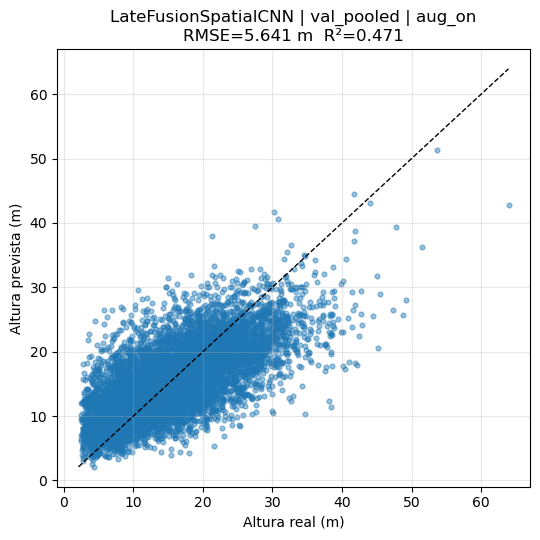

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\LateFusionSpatialCNN_val_pooled_aug_on_residuos.png


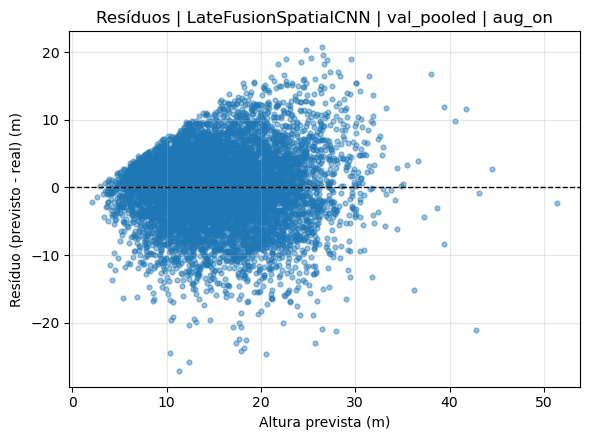

Histograma — aug_on | N real=7561 | N previsto=7561
Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\hist_real_vs_previsto_aug_on.png


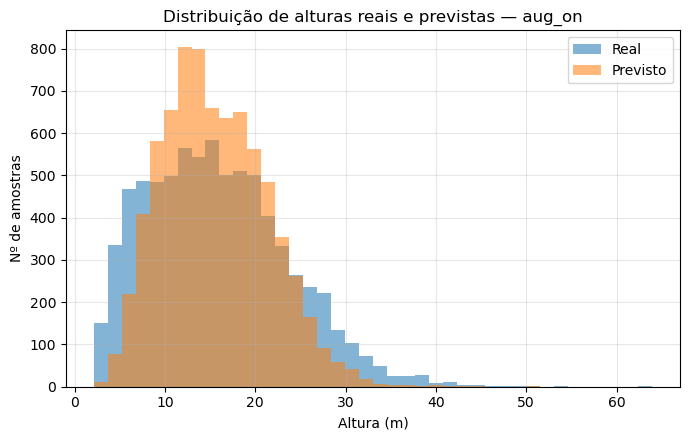

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\rmse_por_regiao_aug_on.png


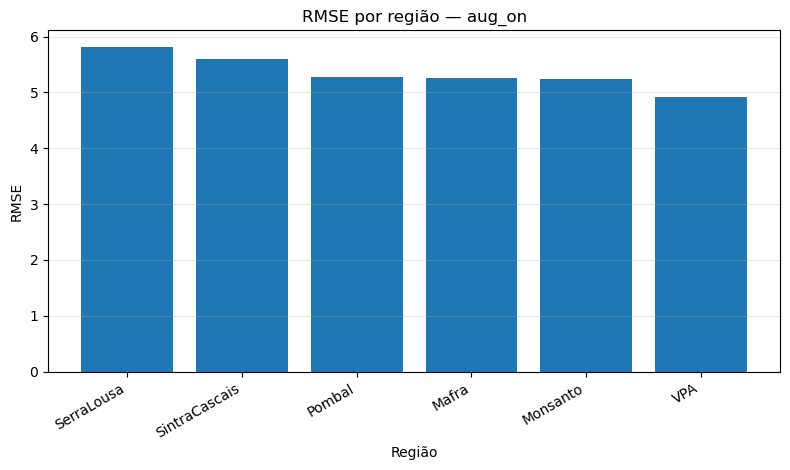

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\r2_por_regiao_aug_on.png


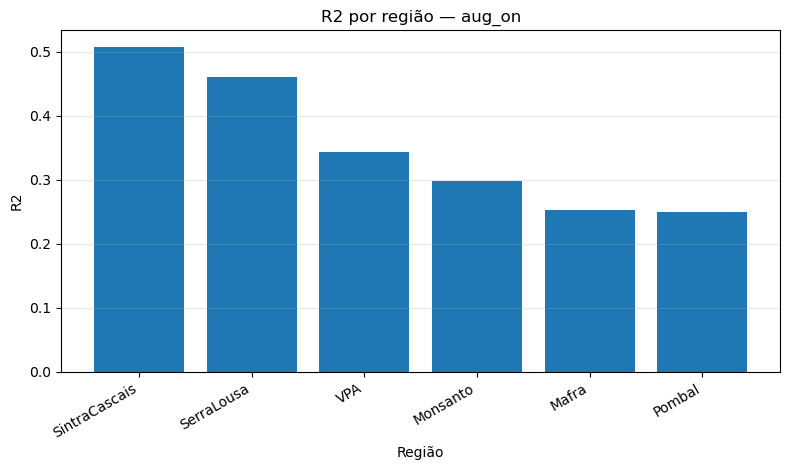

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\rmse_por_classe_altura_aug_on.png


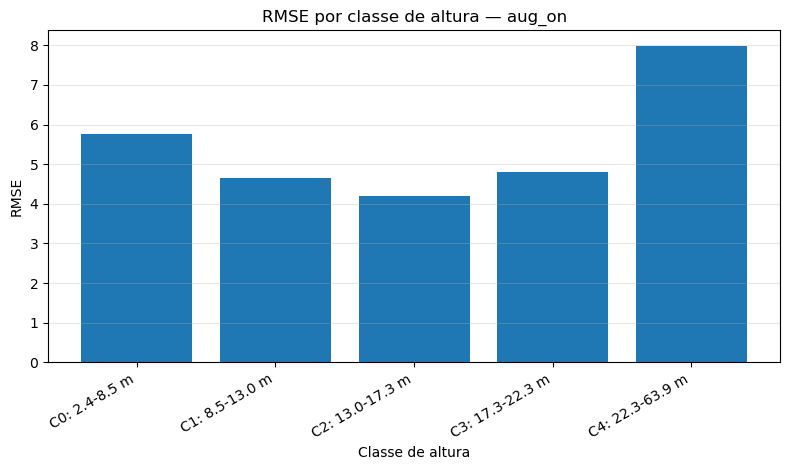

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\bias_por_classe_altura_aug_on.png


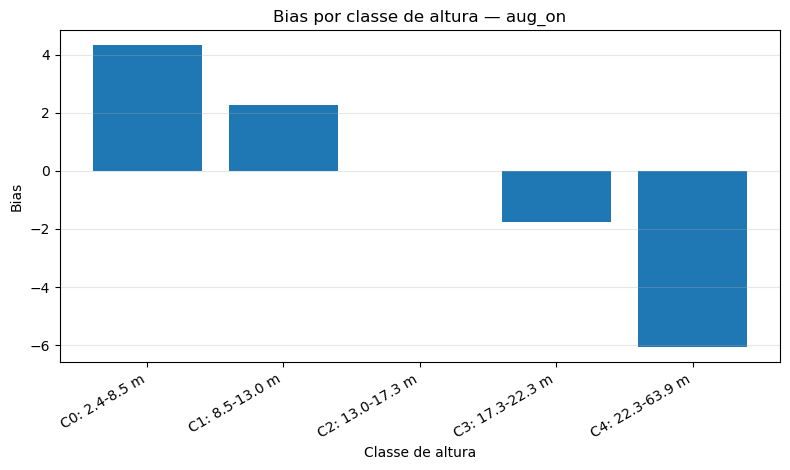

C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:209: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=regions, showfliers=False)


Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\boxplot_residuos_por_regiao_aug_on.png


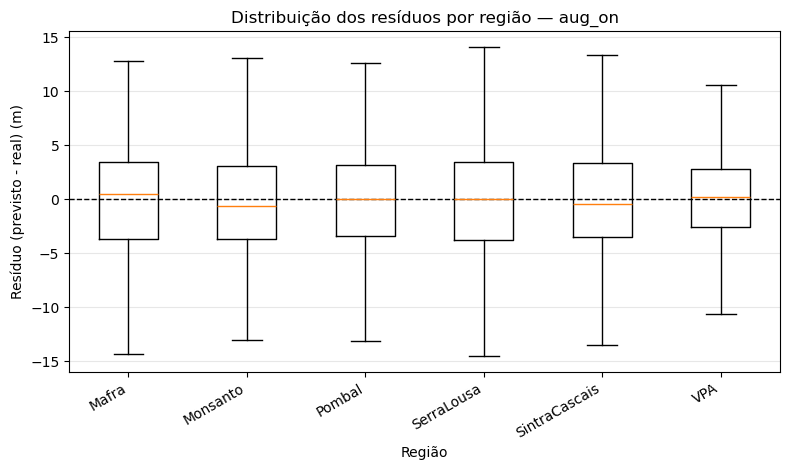

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\boxplot_residuos_por_classe_altura_aug_on.png

C:\Users\gui\AppData\Local\Temp\ipykernel_9320\393947773.py:191: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


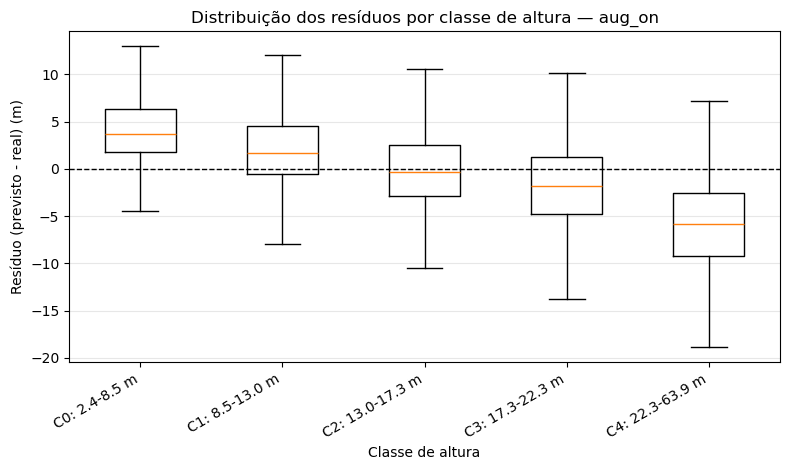

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\evolucao_media_val_rmse_aug_on.png


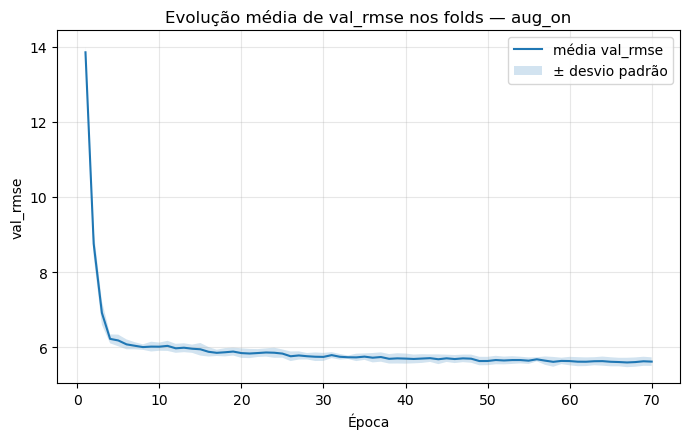

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21\figuras\evolucao_media_val_r2_aug_on.png


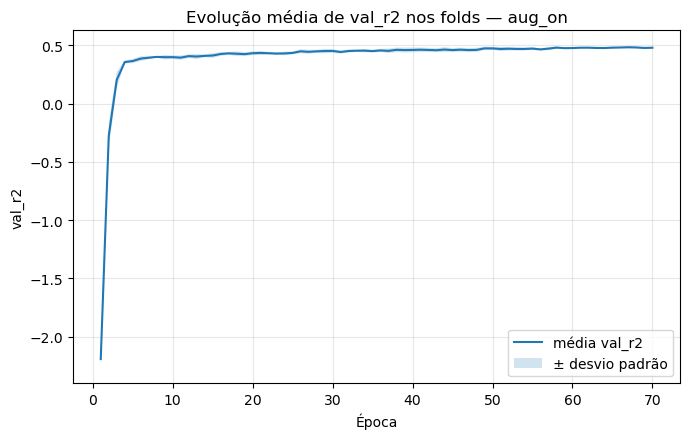


Resultados do patch 21x21 guardados em: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\patch_21x21

 COMPARAÇÃO FINAL ENTRE PATCH SIZES


patch_size augmentation                 model       n      RMSE            \
                                                   mean      mean       std   
0          3       aug_on  LateFusionSpatialCNN  1512.2  5.741144  0.107393   
1          5       aug_on  LateFusionSpatialCNN  1512.2  5.677257  0.139894   
2          7       aug_on  LateFusionSpatialCNN  1512.2  5.604970  0.082868   
3         11       aug_on  LateFusionSpatialCNN  1512.2  5.563309  0.077209   
4         15       aug_on  LateFusionSpatialCNN  1512.2  5.568478  0.064827   
5         21       aug_on  LateFusionSpatialCNN  1512.2  5.639462  0.123099   

       %RMSE                 MAE                  R2                Bias  \
        mean       std      mean       std      mean       std      mean   
0  36.271839  0.531152  4.405655  0.051673  0.451655  0.009074 -0.265158   
1  35.867524  0.738844  4.370777  0.076309  0.463759  0.016292 -0.307942   
2  35.412171  0.405113  4.311469  0.050195  0.477319  0.007527 -0.255904   
3  35.149905  0.462144  4.274519  0.076047  0.484962  0.013011 -0.264280   
4  35.182224  0.336143  4.292660  0.057300  0.484054  0.008666 -0.161954   
5  35.629898  0.689970  4.353004  0.085476  0.470710  0.020394 -0.253127   

             
        std  
0  0.197803  
1  0.210844  
2  0.051489  
3  0.104203  
4  0.193003  
5  0.132533

Figura guardada: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation\comparacao_rmse_patch_sizes_aug_on.png


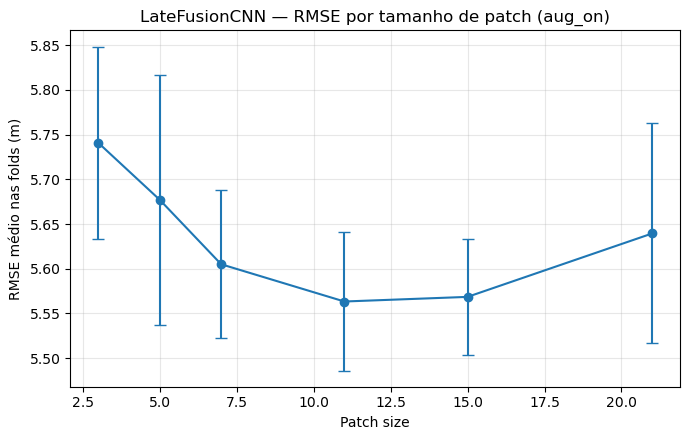


Resultados finais guardados em: outputs_fch\spacial_cnn\cv_global_misturado_late_fusion_cnn_patch_size_ablation


In [8]:
# ============================================================
# 8. FUNÇÕES AUXILIARES PARA CV GLOBAL ESTRATIFICADA
# ============================================================

def make_height_classes(y, n_bins=5):
    """
    Cria classes de altura por quantis.

    Com n_bins=5:
      classe 0 = alturas mais baixas
      classe 4 = alturas mais altas
    """
    y = np.asarray(y, dtype=float)

    if len(y) == 0:
        raise ValueError("y está vazio.")

    if len(np.unique(y)) < 2 or n_bins <= 1:
        classes = np.zeros(len(y), dtype=int)
        bins = np.array([np.min(y), np.max(y)])
        return classes, bins

    classes, bins = pd.qcut(
        pd.Series(y),
        q=n_bins,
        labels=False,
        duplicates="drop",
        retbins=True,
    )

    classes = classes.astype(int).to_numpy()
    return classes, bins


def choose_region_height_strata_for_cv(y, regions, n_splits=5, max_bins=5):
    """
    Cria estratos combinados região + classe_altura.

    Isto tenta garantir que cada fold tem:
      - proporção semelhante de pontos de cada região;
      - proporção semelhante de classes de altura;
      - proporção semelhante de cada combinação região/classe_altura.
    """
    y = np.asarray(y, dtype=float)
    regions = np.asarray(regions)

    if len(y) < n_splits:
        raise ValueError(
            f"Dataset tem apenas {len(y)} amostras. "
            f"Não dá para fazer {n_splits} folds."
        )

    max_bins_possible = min(max_bins, len(np.unique(y)), len(y))

    for n_bins in range(max_bins_possible, 0, -1):
        height_classes, bin_edges = make_height_classes(y, n_bins=n_bins)

        strata = np.array([
            f"{region}__h{height_class}"
            for region, height_class in zip(regions, height_classes)
        ])

        counts = pd.Series(strata).value_counts()

        if counts.min() >= n_splits:
            if n_bins < max_bins:
                print(
                    f"AVISO global: reduzi as classes de altura de "
                    f"{max_bins} para {n_bins}, porque havia combinações "
                    f"região/classe_altura com menos de {n_splits} amostras."
                )

            return height_classes, strata, bin_edges

    min_region_count = pd.Series(regions).value_counts().min()

    raise ValueError(
        "Não foi possível criar estratos região + altura para "
        f"{n_splits} folds. A região mais pequena tem {min_region_count} amostras. "
        "Confirma se todas as regiões têm pelo menos 5 pontos e se não há "
        "combinações região/classe_altura demasiado raras."
    )


def print_height_bins(bin_edges, target_scale=100.0):
    """Mostra os limites das classes de altura em metros."""
    print("\nLimites das classes de altura:")

    for i in range(len(bin_edges) - 1):
        lo = bin_edges[i] / target_scale
        hi = bin_edges[i + 1] / target_scale
        print(f"  Classe {i}: {lo:.2f} m até {hi:.2f} m")


def build_loaders_from_indices(X_all, y_all, train_idx, val_idx, train_transform=None):
    """
    Normaliza sem leakage e cria DataLoaders.

    A média e o desvio padrão são calculados apenas com o treino do fold.
    A validação nunca recebe data augmentation.
    """
    X_train, X_val, _, _ = normalize_from_train(
        X_all[train_idx],
        X_all[val_idx],
    )

    y_train = y_all[train_idx] / TARGET_SCALE
    y_val = y_all[val_idx] / TARGET_SCALE

    print(
        f"\ny_train: média={y_train.mean():.3f}m | std={y_train.std():.3f}m | "
        f"min={y_train.min():.2f}m | max={y_train.max():.2f}m"
    )
    print(
        f"y_val:   média={y_val.mean():.3f}m | std={y_val.std():.3f}m | "
        f"min={y_val.min():.2f}m | max={y_val.max():.2f}m"
    )

    train_ds = FCHDataset(X_train, y_train, transform=train_transform)
    val_ds = FCHDataset(X_val, y_val)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=(len(train_ds) % BATCH_SIZE == 1),
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return train_loader, val_loader


def run_fold(
    X_all,
    y_all,
    regions_all,
    pids_all,
    height_classes_all,
    train_idx,
    val_idx,
    model_name,
    fold_label,
    augmentation_mode,
    train_transform=None,
    result_extra=None,
):
    """Treina e avalia um fold."""
    result_extra = result_extra or {}

    print("\n" + "=" * 70)
    print(f" {fold_label} | augmentation={augmentation_mode}")
    print("=" * 70)
    print(f"Treino: {len(train_idx)} amostras")
    print(f"Validação: {len(val_idx)} amostras")
    print(f"Regiões treino: {sorted(set(regions_all[train_idx]))}")
    print(f"Regiões validação: {sorted(set(regions_all[val_idx]))}")

    set_seed(SEED)

    train_loader, val_loader = build_loaders_from_indices(
        X_all,
        y_all,
        train_idx,
        val_idx,
        train_transform=train_transform,
    )

    num_channels = X_all.shape[1]
    model = LateFusionSpatialCNN(in_channels=num_channels, channel_groups=CHANNEL_GROUPS)

    print("\nArquitetura: LateFusionSpatialCNN")
    count_parameters(model)

    model, history = train_spacialcnn_cnn(
        model,
        train_loader,
        val_loader,
        model_name=model_name,
        epochs=EPOCHS,
        patience=PATIENCE,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        log_every=LOG_EVERY,
    )

    results_df, preds = evaluate_model(
        model,
        val_loader,
        model_name="LateFusionSpatialCNN",
    )

    for key, value in result_extra.items():
        results_df[key] = value

    results_df["augmentation"] = augmentation_mode
    results_df["n_train"] = len(train_idx)
    results_df["n_val"] = len(val_idx)

    val_row = results_df[results_df["split"] == "val"].iloc[0]

    print(
        f"\n>>> Validação Final | RMSE={val_row['RMSE']:.3f}m | "
        f"%RMSE={val_row['%RMSE']:.1f}% | MAE={val_row['MAE']:.3f}m | "
        f"R²={val_row['R2']:.3f}"
    )

    y_true_val = preds["val"]["y_true"]
    y_pred_val = preds["val"]["y_pred"]

    predictions_df = pd.DataFrame({
        "cv_type": result_extra.get("cv_type", "global_region_height_stratified"),
        "augmentation": augmentation_mode,
        "fold": result_extra.get("fold", np.nan),
        "region": regions_all[val_idx],
        "point_id": pids_all[val_idx],
        "height_class": height_classes_all[val_idx],
        "y_true_m": y_true_val,
        "y_pred_m": y_pred_val,
    })

    predictions_df["residual_m"] = predictions_df["y_pred_m"] - predictions_df["y_true_m"]
    predictions_df["abs_error_m"] = predictions_df["residual_m"].abs()

    if PLOT_EACH_FOLD:
        plot_learning_curves(
            history,
            model_name=model_name,
            split_label=fold_label,
        )

        plot_true_vs_pred(
            y_true_val,
            y_pred_val,
            model_name="LateFusionSpatialCNN",
            split_name="val",
            split_label=f"{augmentation_mode}_fold{result_extra.get('fold', '')}",
        )

        plot_residuals(
            y_true_val,
            y_pred_val,
            model_name="LateFusionSpatialCNN",
            split_name="val",
            split_label=f"{augmentation_mode}_fold{result_extra.get('fold', '')}",
        )

    return results_df, history, predictions_df


def summarize_final_results(final_df, group_cols):
    """Resumo de métricas por fold: média e desvio padrão."""
    metric_cols = ["RMSE", "%RMSE", "MAE", "R2", "Bias", "Covariancia"]

    summary = (
        final_df[final_df["split"] == "val"]
        .groupby(group_cols)[metric_cols]
        .agg(["mean", "std"])
    )

    display(summary)
    return summary


def grouped_regression_metrics(predictions_df, group_cols):
    """
    Calcula métricas agrupadas usando as previsões pooled de todos os folds.

    Cada ponto aparece uma vez na validação, porque é 5-fold CV.
    """
    rows = []

    for group_values, df_group in predictions_df.groupby(group_cols):
        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        metrics = regression_metrics(
            df_group["y_true_m"].to_numpy(),
            df_group["y_pred_m"].to_numpy(),
        )

        row = {
            col: value
            for col, value in zip(group_cols, group_values)
        }
        row.update(metrics)

        rows.append(row)

    return pd.DataFrame(rows)


def grouped_cv_meanstd_metrics(predictions_df, group_cols):
    """
    Calcula métricas por fold e depois resume por média ± desvio padrão.

    Útil para ver estabilidade das métricas por região ou por classe.
    """
    per_fold_rows = []

    for group_values, df_group in predictions_df.groupby(["fold"] + group_cols):
        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        fold = group_values[0]
        values = group_values[1:]

        metrics = regression_metrics(
            df_group["y_true_m"].to_numpy(),
            df_group["y_pred_m"].to_numpy(),
        )

        row = {"fold": fold}
        row.update({
            col: value
            for col, value in zip(group_cols, values)
        })
        row.update(metrics)

        per_fold_rows.append(row)

    per_fold_df = pd.DataFrame(per_fold_rows)

    metric_cols = ["RMSE", "%RMSE", "MAE", "R2", "Bias", "Covariancia"]

    summary = (
        per_fold_df
        .groupby(group_cols)[metric_cols]
        .agg(["mean", "std"])
        .reset_index()
    )

    return per_fold_df, summary


# ============================================================
# 9. PIPELINE — CV GLOBAL MISTURADO + ABLATION POR PATCH SIZE
# ============================================================

def run_latefusion_for_patch_size(
    patch_size,
    allowed_region_point_ids=None,
):
    """
    Corre o pipeline completo LateFusionCNN para um tamanho de patch.
    Guarda resultados numa subpasta própria.
    """
    global OUTPUT_DIR, PLOTS_DIR, CHANNEL_GROUPS

    raw_base_dir = PATCH_BASE_DIR / f"patch_{patch_size}x{patch_size}"
    OUTPUT_DIR = OUTPUT_BASE_DIR / f"patch_{patch_size}x{patch_size}"
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # PLOTS_DIR é usado pelas funções de gráficos definidas na célula anterior.
    PLOTS_DIR = OUTPUT_DIR / "figuras"

    print("\n" + "=" * 80)
    print(f" PIPELINE FCH — LateFusionSpatialCNN — PATCH {patch_size}x{patch_size}")
    print(" CV: global misturado | estratificação: região + classe de altura")
    print(f" Pasta de entrada: {raw_base_dir}")
    print(f" Pasta de saída:   {OUTPUT_DIR}")
    print("=" * 80)

    X_all, y_all, regions_all, pids_all, band_names_ref = load_all_regions_tifs(
        raw_base_dir,
        VALIDATION_DIR,
        target_column=TARGET_COLUMN,
        allowed_region_point_ids=allowed_region_point_ids,
    )

    available_regions = sorted(np.unique(regions_all))
    print(f"\nRegiões disponíveis: {available_regions}")
    print(f"N amostras usadas neste patch size: {len(y_all)}")

    CHANNEL_GROUPS = infer_late_fusion_channel_groups(band_names_ref)

    height_classes, strata, bin_edges = choose_region_height_strata_for_cv(
        y_all,
        regions_all,
        n_splits=N_SPLITS,
        max_bins=N_HEIGHT_BINS,
    )

    print_height_bins(bin_edges, target_scale=TARGET_SCALE)

    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED,
    )

    cv_splits = list(skf.split(X_all, strata))

    fold_ids = np.full(len(y_all), fill_value=-1, dtype=int)
    for fold, (_, val_idx) in enumerate(cv_splits, start=1):
        fold_ids[val_idx] = fold

    fold_assignments_df = pd.DataFrame({
        "patch_size": patch_size,
        "region": regions_all,
        "point_id": pids_all,
        "y_cm": y_all,
        "y_m": y_all / TARGET_SCALE,
        "height_class": height_classes,
        "stratum": strata,
        "fold": fold_ids,
    })

    # ============================================================
    # VERIFICAÇÃO DA ESTRATIFICAÇÃO
    # ============================================================

    print("\n=== Distribuição de regiões por fold ===")
    display(pd.crosstab(fold_assignments_df["fold"], fold_assignments_df["region"]))

    print("\n=== Distribuição de classes de altura por fold ===")
    display(pd.crosstab(fold_assignments_df["fold"], fold_assignments_df["height_class"]))

    print("\n=== Distribuição região × classe de altura por fold ===")
    display(
        pd.crosstab(
            fold_assignments_df["fold"],
            [fold_assignments_df["region"], fold_assignments_df["height_class"]],
        )
    )

    # ============================================================
    # TREINO DAS EXPERIÊNCIAS
    # ============================================================

    all_results = []
    all_predictions = []
    all_histories = {}

    for augmentation_mode in ABLATION_AUGMENTATION_MODES:
        print("\n" + "#" * 70)
        print(f" PATCH {patch_size}x{patch_size} | EXPERIÊNCIA: {augmentation_mode}")
        print("#" * 70)

        train_transform = get_train_transform(augmentation_mode)

        for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
            model_name = f"LateFusionSpatialCNN_patch{patch_size}x{patch_size}_{augmentation_mode}_fold{fold}"
            fold_label = f"Patch {patch_size}x{patch_size} | Fold {fold}/{N_SPLITS}"

            results_df, history, predictions_df = run_fold(
                X_all=X_all,
                y_all=y_all,
                regions_all=regions_all,
                pids_all=pids_all,
                height_classes_all=height_classes,
                train_idx=train_idx,
                val_idx=val_idx,
                model_name=model_name,
                fold_label=fold_label,
                augmentation_mode=augmentation_mode,
                train_transform=train_transform,
                result_extra={
                    "cv_type": "global_region_height_stratified",
                    "patch_size": patch_size,
                    "patch_area_m": patch_size * 25,
                    "fold": fold,
                },
            )

            # run_fold não copia automaticamente todos os result_extra para predictions_df.
            predictions_df["patch_size"] = patch_size
            predictions_df["patch_area_m"] = patch_size * 25

            all_results.append(results_df)
            all_predictions.append(predictions_df)

            # Manter chave com 2 valores para compatibilidade com plot_cv_metric_evolution.
            all_histories[(augmentation_mode, fold)] = history

    # ============================================================
    # RESUMOS FINAIS DESTE PATCH SIZE
    # ============================================================

    final_df = pd.concat(all_results, ignore_index=True)
    predictions_df = pd.concat(all_predictions, ignore_index=True)

    print("\n=== Resultados por fold ===")
    display(final_df)

    print("\n=== Resumo global por experiência — média ± desvio padrão das 5 folds ===")
    summary_global = summarize_final_results(
        final_df,
        group_cols=["patch_size", "augmentation", "model"],
    )

    print("\n=== Métricas por região — pooled predictions ===")
    metrics_by_region = grouped_regression_metrics(
        predictions_df,
        group_cols=["patch_size", "augmentation", "region"],
    )
    display(metrics_by_region)

    print("\n=== Métricas por classe de altura — pooled predictions ===")
    metrics_by_height_class = grouped_regression_metrics(
        predictions_df,
        group_cols=["patch_size", "augmentation", "height_class"],
    )
    display(metrics_by_height_class)

    print("\n=== Métricas por região — média ± desvio padrão entre folds ===")
    metrics_region_per_fold, metrics_region_cv_summary = grouped_cv_meanstd_metrics(
        predictions_df,
        group_cols=["patch_size", "augmentation", "region"],
    )
    display(metrics_region_cv_summary)

    print("\n=== Métricas por classe de altura — média ± desvio padrão entre folds ===")
    metrics_height_per_fold, metrics_height_cv_summary = grouped_cv_meanstd_metrics(
        predictions_df,
        group_cols=["patch_size", "augmentation", "height_class"],
    )
    display(metrics_height_cv_summary)

    print("\n=== Comparação direta da ablation augmentation ===")
    ablation_comparison = (
        final_df[final_df["split"] == "val"]
        .groupby(["patch_size", "augmentation"])[["RMSE", "%RMSE", "MAE", "R2", "Bias"]]
        .agg(["mean", "std"])
    )
    display(ablation_comparison)

    # ============================================================
    # GRÁFICOS FINAIS DESTE PATCH SIZE
    # ============================================================

    plot_all_final_figures(
        predictions_df=predictions_df,
        metrics_by_region=metrics_by_region,
        metrics_by_height_class=metrics_by_height_class,
        all_histories=all_histories,
        bin_edges=bin_edges,
    )

    # ============================================================
    # GUARDAR RESULTADOS DESTE PATCH SIZE
    # ============================================================

    final_df.to_csv(
        OUTPUT_DIR / "resultados_cv_global_misturado_ablation.csv",
        index=False,
    )

    predictions_df.to_csv(
        OUTPUT_DIR / "predicoes_cv_global_misturado_ablation.csv",
        index=False,
    )

    fold_assignments_df.to_csv(
        OUTPUT_DIR / "fold_assignments_cv_global_misturado.csv",
        index=False,
    )

    summary_global.to_csv(
        OUTPUT_DIR / "resumo_global_cv_global_misturado_ablation.csv",
    )

    metrics_by_region.to_csv(
        OUTPUT_DIR / "metricas_por_regiao_pooled.csv",
        index=False,
    )

    metrics_by_height_class.to_csv(
        OUTPUT_DIR / "metricas_por_classe_altura_pooled.csv",
        index=False,
    )

    metrics_region_per_fold.to_csv(
        OUTPUT_DIR / "metricas_por_regiao_por_fold.csv",
        index=False,
    )

    metrics_region_cv_summary.to_csv(
        OUTPUT_DIR / "metricas_por_regiao_media_std_folds.csv",
        index=False,
    )

    metrics_height_per_fold.to_csv(
        OUTPUT_DIR / "metricas_por_classe_altura_por_fold.csv",
        index=False,
    )

    metrics_height_cv_summary.to_csv(
        OUTPUT_DIR / "metricas_por_classe_altura_media_std_folds.csv",
        index=False,
    )

    ablation_comparison.to_csv(
        OUTPUT_DIR / "comparacao_ablation_augmentation.csv",
    )

    print(f"\nResultados do patch {patch_size}x{patch_size} guardados em: {OUTPUT_DIR}")

    outputs = {
        "patch_size": patch_size,
        "final_df": final_df,
        "predictions_df": predictions_df,
        "summary_global": summary_global,
        "metrics_by_region": metrics_by_region,
        "metrics_by_height_class": metrics_by_height_class,
        "metrics_region_per_fold": metrics_region_per_fold,
        "metrics_region_cv_summary": metrics_region_cv_summary,
        "metrics_height_per_fold": metrics_height_per_fold,
        "metrics_height_cv_summary": metrics_height_cv_summary,
        "fold_assignments_df": fold_assignments_df,
    }

    # Libertar memória antes do próximo patch size.
    del X_all, y_all, regions_all, pids_all
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return outputs


# ============================================================
# 10. CORRER TODOS OS PATCH SIZES
# ============================================================

import gc

print("=" * 80)
print(" LATE FUSION CNN — ABLATION POR TAMANHO DE PATCH")
print(f" Patch sizes: {PATCH_SIZES_TO_RUN}")
print(f" Common points across patch sizes: {USE_COMMON_POINTS_ACROSS_PATCH_SIZES}")
print("=" * 80)

allowed_common_ids = None
ids_by_patch_size = None

if USE_COMMON_POINTS_ACROSS_PATCH_SIZES:
    allowed_common_ids, ids_by_patch_size = find_common_region_point_ids(
        PATCH_BASE_DIR,
        PATCH_SIZES_TO_RUN,
        VALIDATION_DIR,
        target_column=TARGET_COLUMN,
    )

    common_ids_df = pd.DataFrame(
        sorted(list(allowed_common_ids)),
        columns=["region", "point_id"],
    )
    common_ids_df.to_csv(
        OUTPUT_BASE_DIR / "common_region_point_ids_across_patch_sizes.csv",
        index=False,
    )

patch_outputs = []

for patch_size in PATCH_SIZES_TO_RUN:
    outputs = run_latefusion_for_patch_size(
        patch_size,
        allowed_region_point_ids=allowed_common_ids,
    )
    patch_outputs.append(outputs)


# ============================================================
# 11. COMPARAÇÃO FINAL ENTRE PATCH SIZES
# ============================================================

all_final_df = pd.concat(
    [o["final_df"] for o in patch_outputs],
    ignore_index=True,
)

all_predictions_df = pd.concat(
    [o["predictions_df"] for o in patch_outputs],
    ignore_index=True,
)

all_region_metrics_df = pd.concat(
    [o["metrics_by_region"] for o in patch_outputs],
    ignore_index=True,
)

all_height_metrics_df = pd.concat(
    [o["metrics_by_height_class"] for o in patch_outputs],
    ignore_index=True,
)

print("\n" + "=" * 80)
print(" COMPARAÇÃO FINAL ENTRE PATCH SIZES")
print("=" * 80)

comparison_patch_sizes = (
    all_final_df[all_final_df["split"] == "val"]
    .groupby(["patch_size", "augmentation", "model"])
    [["n", "RMSE", "%RMSE", "MAE", "R2", "Bias"]]
    .agg({
        "n": "mean",
        "RMSE": ["mean", "std"],
        "%RMSE": ["mean", "std"],
        "MAE": ["mean", "std"],
        "R2": ["mean", "std"],
        "Bias": ["mean", "std"],
    })
    .reset_index()
)

display(comparison_patch_sizes)

OUTPUT_BASE_DIR.mkdir(parents=True, exist_ok=True)

all_final_df.to_csv(
    OUTPUT_BASE_DIR / "TODOS_resultados_cv_por_patch_size.csv",
    index=False,
)

all_predictions_df.to_csv(
    OUTPUT_BASE_DIR / "TODAS_predicoes_cv_por_patch_size.csv",
    index=False,
)

all_region_metrics_df.to_csv(
    OUTPUT_BASE_DIR / "comparacao_patch_size_por_regiao.csv",
    index=False,
)

all_height_metrics_df.to_csv(
    OUTPUT_BASE_DIR / "comparacao_patch_size_por_classe_altura.csv",
    index=False,
)

comparison_patch_sizes.to_csv(
    OUTPUT_BASE_DIR / "comparacao_final_patch_sizes.csv",
    index=False,
)

# Gráfico simples de comparação RMSE por patch size.
plot_df = (
    all_final_df[all_final_df["split"] == "val"]
    .groupby(["patch_size", "augmentation"])["RMSE"]
    .agg(["mean", "std"])
    .reset_index()
)

for augmentation_mode in sorted(plot_df["augmentation"].unique()):
    df_mode = plot_df[plot_df["augmentation"] == augmentation_mode].sort_values("patch_size")

    plt.figure(figsize=(7, 4.5))
    plt.errorbar(
        df_mode["patch_size"],
        df_mode["mean"],
        yerr=df_mode["std"],
        marker="o",
        capsize=4,
    )
    plt.xlabel("Patch size")
    plt.ylabel("RMSE médio nas folds (m)")
    plt.title(f"LateFusionCNN — RMSE por tamanho de patch ({augmentation_mode})")
    plt.grid(alpha=0.3)

    fig_path = OUTPUT_BASE_DIR / f"comparacao_rmse_patch_sizes_{augmentation_mode}.png"
    plt.tight_layout()
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    print(f"Figura guardada: {fig_path}")
    plt.show()

print(f"\nResultados finais guardados em: {OUTPUT_BASE_DIR}")
